# From FaIR emissions to synthetic North Atlantic tropical cyclones

Follow one September in 2050 from global warming to storm motion. FaIR turns the SSP2-4.5 pathway into a global temperature. A regional emulator draws an ocean–atmosphere background in EOF coordinates and evolves daily winds with a linear inverse model (LIM). Coupled FAST moves and intensifies disturbances in those fields.

Sections 1–5 run the published v1 LIM and the TC package's native hourly Fourier winds. In section 6, compare the September displacement distributions from v1 and the 57-year Research LIM against storms driven by daily MPI winds. Section 7 follows both LIMs through all twelve months of 2050. Section 8 compares what changed in storm intensity, formation, the ocean fields and steering winds.

**To run the tutorial**, install the release weights and `requirements-notebook.txt`, then select **Restart Kernel and Run All**. The repository includes the scenario inputs, one MPI reference month, the benchmark's six-hourly tracks and the geographic grids. Figures and tables are written to `runs/fair_to_tc/`. The sample-size settings below control the small live experiment in sections 1–4. The eight-member MPI benchmark has its own fixed design. [Weight installation](../README.md) · [Regional model derivation](../reports/annual_lim_linear_algebra.md) · [MPI benchmark](../reports/mpi2050/README.md)

In [1]:
import os
import sys
from pathlib import Path
for key in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/annual_lim/model.py").is_file())
sys.path[:0] = [str(root / "src"), str(root / "notebooks")]
candidates = [Path(os.environ["ANNUAL_LIM_WEIGHTS"])] if "ANNUAL_LIM_WEIGHTS" in os.environ else []
candidates += [root / "weights", root / "runs/annual_lim/weights", root / "work/weights"]
weights = next((p for p in candidates
                if (p / "09/model.json").is_file()), None)
if weights is None:
    raise FileNotFoundError("Install the v1.0.0 weights using the command in README.md.")
data = root / "notebooks/data"
out = root / "runs/fair_to_tc"
out.mkdir(parents=True, exist_ok=True)

import hashlib
import json
import multiprocessing as mp
import platform
from concurrent.futures import ProcessPoolExecutor
from importlib.metadata import version
from time import perf_counter

%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from threadpoolctl import threadpool_limits
from annual_lim.model import MonthlyModel
from annual_lim.sample import event, forcing
from tc_emulator.sampling import fair_years
from tc_emulator.tc_adapter import geography
from tc_benchmark import DAYS, METHODS, MONTH, paired_rates, run_pair

threads = threadpool_limits(limits=1)
seed = 20261119
historical_years = list(range(1985, 2021, 5))
future_year = 2050
future_events = 8
seeds_per_event = 128
workers = max(1, int(os.environ.get("TC_DEMO_WORKERS", "2")))
manifest = json.loads((data / "sources.json").read_text())
for filename, expected in manifest["sha256"].items():
    assert hashlib.sha256((data / filename).read_bytes()).hexdigest() == expected
assert version("fair") == manifest["fair"]["version"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
                     "axes.titlelocation": "left", "font.size": 10, "savefig.dpi": 150})
colors = {"Pure LIM": "#007875", "Native Fourier": "#ba532b"}
print(f"{len(historical_years)} historical + {future_events} future panels, "
      f"{seeds_per_event} seeds per panel, {len(METHODS)} drivers, {workers} workers")

8 historical + 8 future panels, 128 seeds per panel, 2 drivers, 3 workers


## Follow the inputs to FAST

The diagram follows one September from annual global temperature to hourly storm tracks. In the fixed-background experiment, all three drivers use the same MPI ocean, atmosphere and candidate disturbances. In the FaIR-only experiment, LIM and Fourier share a generated background, and the evaluation compares their storm distributions with the separate MPI replay. The section numbers on the right refer to this notebook. [Download the three-page workflow](../reports/annual_lim_math_flow.pdf) · [Worked EOF and LIM equations](Annual_Pure_LIM_Tutorial.ipynb#annual-step-5)

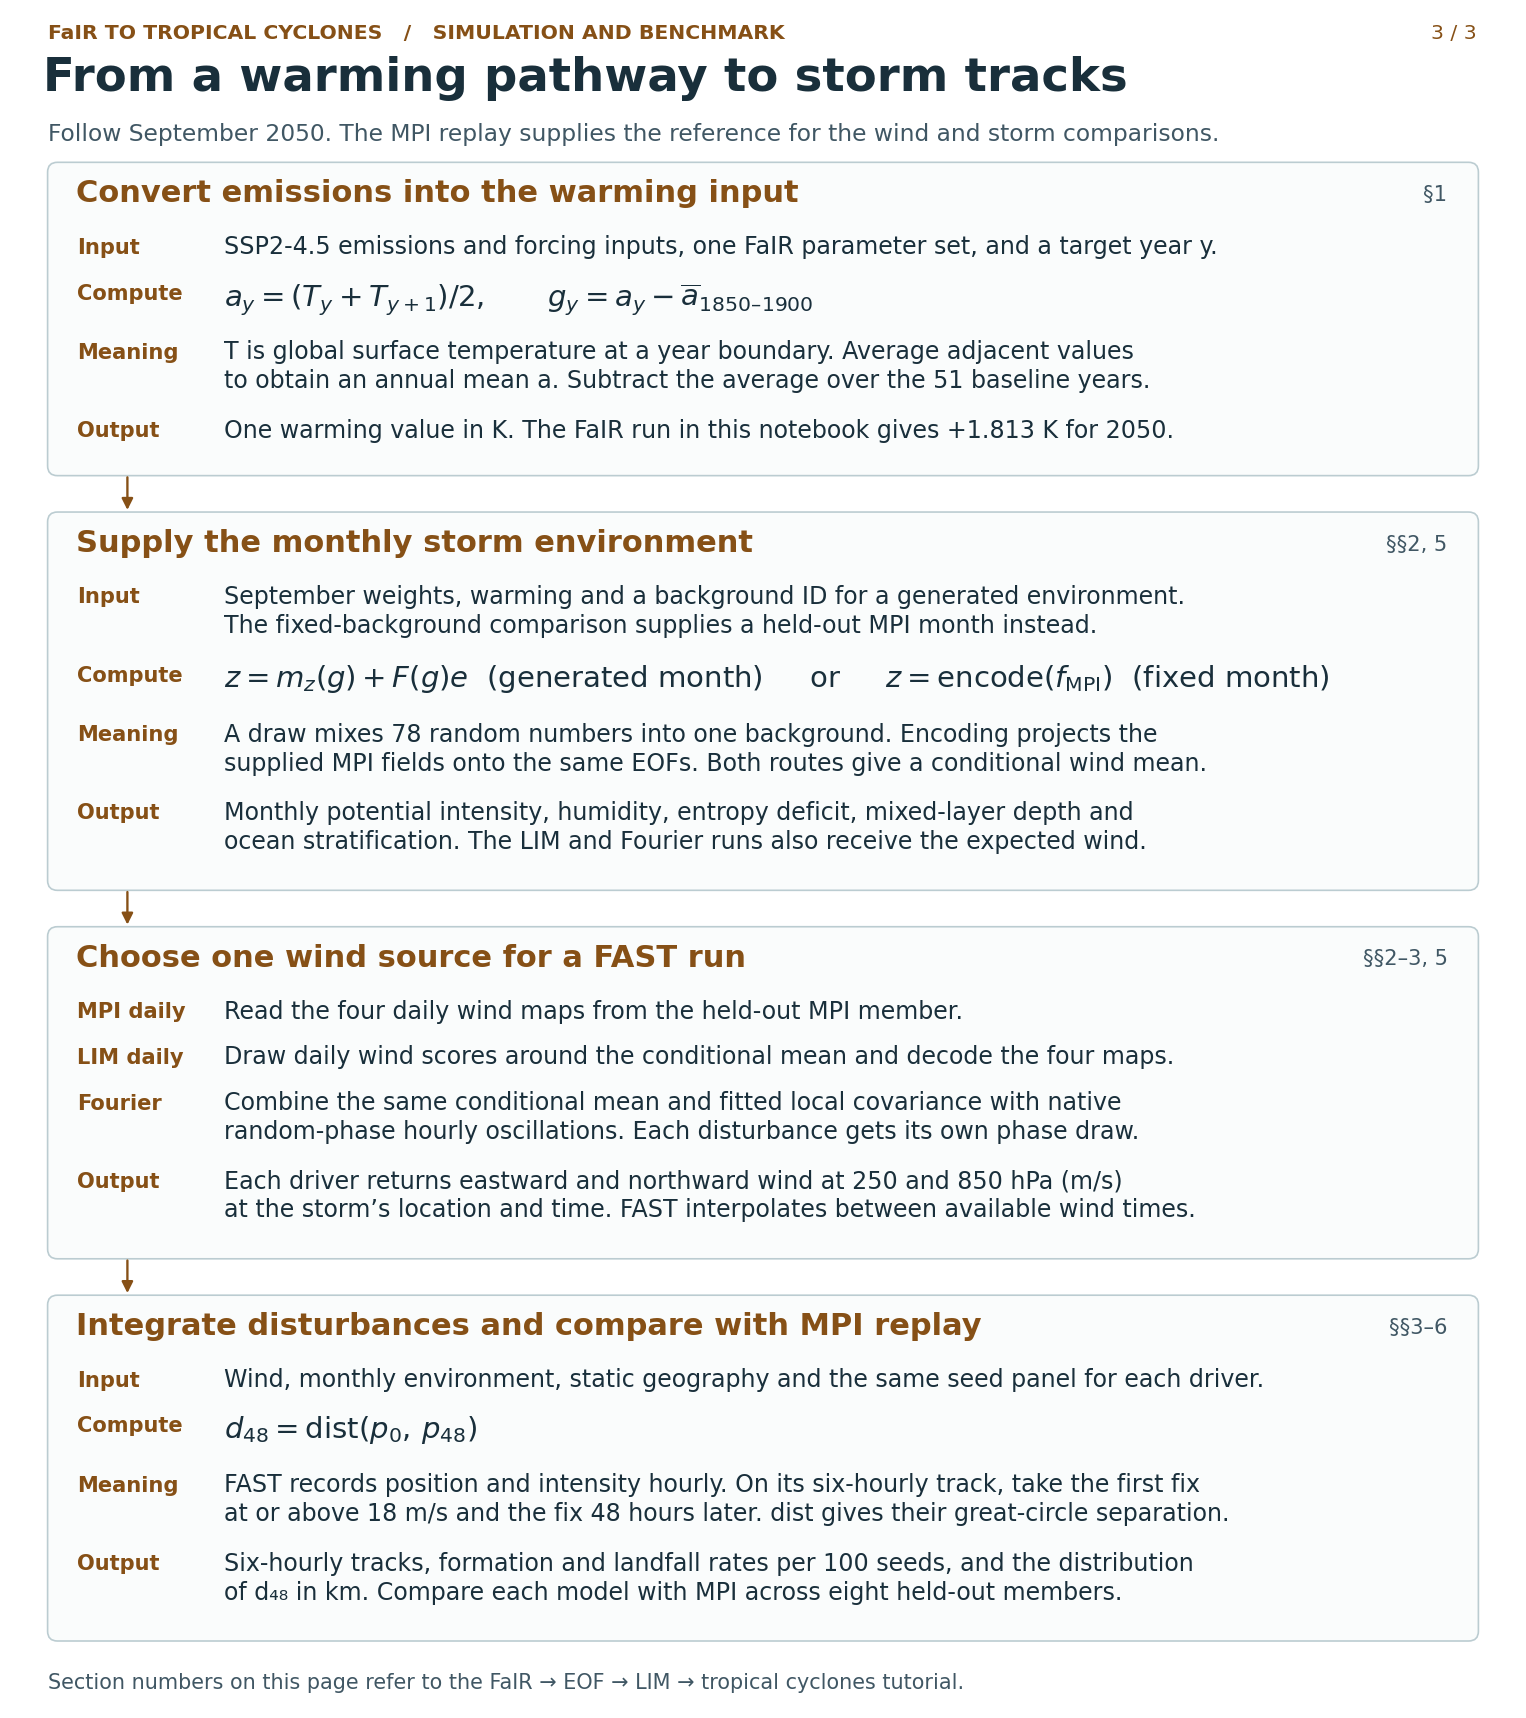

In [2]:
from IPython.display import Image
display(Image(filename=str(root / "reports/annual_lim_tc_flow.png"), width=900,
              alt="FaIR warming selects a September background. MPI daily, LIM daily or Fourier hourly winds then drive identical FAST storm seeds."))

## 1 · Run FaIR on the SSP2-4.5 pathway

The small input archive contains emissions, prescribed concentrations and prescribed radiative forcing in the units and species order expected by FaIR. It can be regenerated from the three original RCMIP tables. It contains no temperature trajectory. Here we run FaIR 2.2.4 with one published parameter configuration (2451, calibration 1.4.1) and turn off stochastic internal temperature noise. This gives one forced global surface air temperature path. The experiment samples regional weather uncertainty separately. [FaIR calibration](https://docs.fairmodel.net/en/v2.2.4/examples/calibrated_constrained_ensemble.html) · [RCMIP 5.1.0](https://doi.org/10.5281/zenodo.4589756) · [Input preparation](prepare_tc_inputs.py)

In [3]:
# FaIR disables its progress bar below, so a Jupyter widget backend is optional.
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*", module="tqdm.auto")
    from fair import FAIR
from fair.interface import fill, initialise
from fair.io import read_properties

start = perf_counter()
fair = FAIR(ch4_method="Thornhill2021")
config_id = 2451
fair.define_time(1750, 2101, 1)
fair.define_scenarios(["ssp245"])
fair.define_configs([config_id])
fair.define_species(*read_properties(filename=data / "fair_species.csv"))
fair.allocate()
with np.load(data / "rcmip_ssp245.npz", allow_pickle=False) as inputs:
    np.testing.assert_array_equal(inputs["species"], fair.species)
    np.testing.assert_array_equal(inputs["timebounds"], fair.timebounds)
    np.testing.assert_array_equal(inputs["timepoints"], fair.timepoints)
    for name in ("emissions", "concentration", "forcing"):
        fill(getattr(fair, name), inputs[name], scenario="ssp245", config=config_id)
fair.fill_species_configs(data / "fair_species.csv")
fair.override_defaults(data / "fair_2451.csv")
fill(fair.climate_configs["stochastic_run"], False)
params = pd.read_csv(data / "fair_2451.csv", index_col=0).loc[config_id]
for name in ("Solar", "Volcanic"):
    fill(fair.forcing, fair.forcing.sel(specie=name) * params[f"forcing_scale[{name}]"], specie=name)
initialise(fair.concentration, fair.species_configs["baseline_concentration"])
for a in (fair.forcing, fair.temperature, fair.cumulative_emissions,
          fair.airborne_emissions, fair.ocean_heat_content_change):
    initialise(a, 0)
fair.run(progress=False)
surface = fair.temperature.sel(scenario="ssp245", config=config_id, layer=0)
fair_seconds = perf_counter() - start
assert np.isfinite(surface).all()
print(f"Ran {len(fair.timepoints)} annual steps, {len(fair.species)} species, one climate configuration.")

Ran 351 annual steps, 61 species, one climate configuration.


FaIR reports temperature at year boundaries. With linear interpolation between adjacent boundaries, the annual mean for year $y$ is $a_y=[T(y)+T(y+1)]/2$. The regional model uses $g_y=a_y-\frac{1}{51}\sum_{j=1850}^{1900}a_j$. The CSV below exercises the same forcing interface as the command-line sampler. A FaIRGP path with the documented columns can use that interface as well.

2050 global warming = 1.813 K relative to 1850–1900


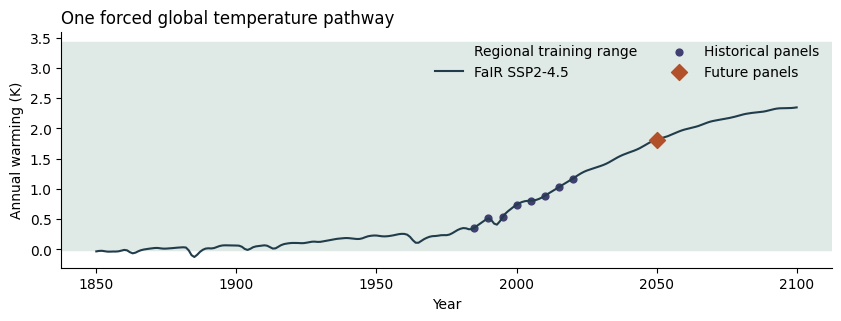

In [4]:
bounds_file = out / "fair_ssp245_timebounds.csv"
pd.DataFrame({"time": fair.timebounds, "forced_temperature": surface.values, "unit": "K",
              "baseline": "1750 initial state", "scenario": "ssp245", "draw_id": str(config_id),
              "temperature_definition": "forced global surface air temperature"}).to_csv(bounds_file, index=False)
warming = fair_years(bounds_file).set_index("year").g
g_future, origin = forcing(None, bounds_file, future_year, "ssp245", str(config_id))
means = (surface.values[:-1] + surface.values[1:]) / 2
years = fair.timebounds[:-1].astype(int)
baseline = means[(years >= 1850) & (years <= 1900)].mean()
np.testing.assert_allclose(warming.loc[years], means - baseline, atol=1e-12)
print(f"{future_year} global warming = {g_future:.3f} K relative to 1850–1900")
model = MonthlyModel(weights, MONTH)
fig, ax = plt.subplots(figsize=(8.3, 3.1), layout="constrained")
ax.axhspan(model.cal.g_min, model.cal.g_max, color="#dfe9e6", label="Regional training range")
ax.plot(warming.loc[1850:], color="#213d4b", label="FaIR SSP2-4.5")
ax.scatter(historical_years, warming.loc[historical_years], color="#413e70", s=24, label="Historical panels")
ax.scatter(future_year, g_future, color="#b25129", s=66, marker="D", label="Future panels", zorder=4)
ax.set(xlabel="Year", ylabel="Annual warming (K)", title="One forced global temperature pathway")
ax.legend(ncol=2, frameon=False)
fig.savefig(out / "warming.png")
plt.show()

## 2 · Decode an EOF background and evolve the wind

The September weights contain regional empirical orthogonal functions (EOFs) fitted to MPI-ESM1-2-LR. The background draw is $z=m(g)+F(g)\epsilon$, where $m(g)$ is the mean vector, $F(g)$ shapes the covariance, and the entries of $\epsilon$ are independent standard normal variates. Decoding converts 78 scores into SST, mixed-layer depth, ocean stratification, pressure and atmospheric profiles. Each map is its training mean plus a weighted sum of EOFs. In panel A, adding one training standard deviation of the first SST score makes the displayed temperature change. Its sign follows the stored EOF convention.

The wind model first samples a stationary Gaussian state with two daily lags, then advances it with a fitted transition matrix and fresh Gaussian innovations. A fitted 5–20 day memory term acts on these states. Adding the background-dependent mean produces 120 daily wind scores. Decoding them gives $u$ and $v$ at 250 and 850 hPa. All disturbances in this LIM event experience the same sequence. [Model equations and estimation](../reports/annual_lim_linear_algebra.md)

In [5]:
demo = event(weights, MONTH, future_year, g_future, DAYS, seed, 0, 0)
z = model.draw_z(g_future, future_year, seed, 0)
np.testing.assert_allclose(z, demo.background_pc)
decoded = model.rep.decode(z[None])
np.testing.assert_allclose(decoded["sst"][0], demo.sst, equal_nan=True)
scores = model.pc_path(g_future, z, DAYS + 3, future_year, seed, 0, 0)
np.testing.assert_allclose(scores, demo.wind_pc)
np.testing.assert_allclose(model.rep.blocks["wind"].inverse(scores), demo.wind)
display(pd.DataFrame([
    {"EOF block": name, "scores": len(block.variance),
     "retained training variance (%)": 100 * block.variance.sum() / block.total_variance}
    for name, block in model.rep.blocks.items()
]).round(1))
print(f"{len(z)} background scores; daily field {demo.wind.shape} (time, component, lat, lon).")
print(f"{DAYS} integration days with wind nodes from day −1 through day {DAYS+1}.")

,EOF block,scores,retained training variance (%)
0,sst,18,89.4
1,ocean,18,56.5
2,psl,14,92.2
3,profiles,28,87.7
4,wind,120,88.0


78 background scores; daily field (18, 4, 36, 58) (time, component, lat, lon).
15 integration days with wind nodes from day −1 through day 16.


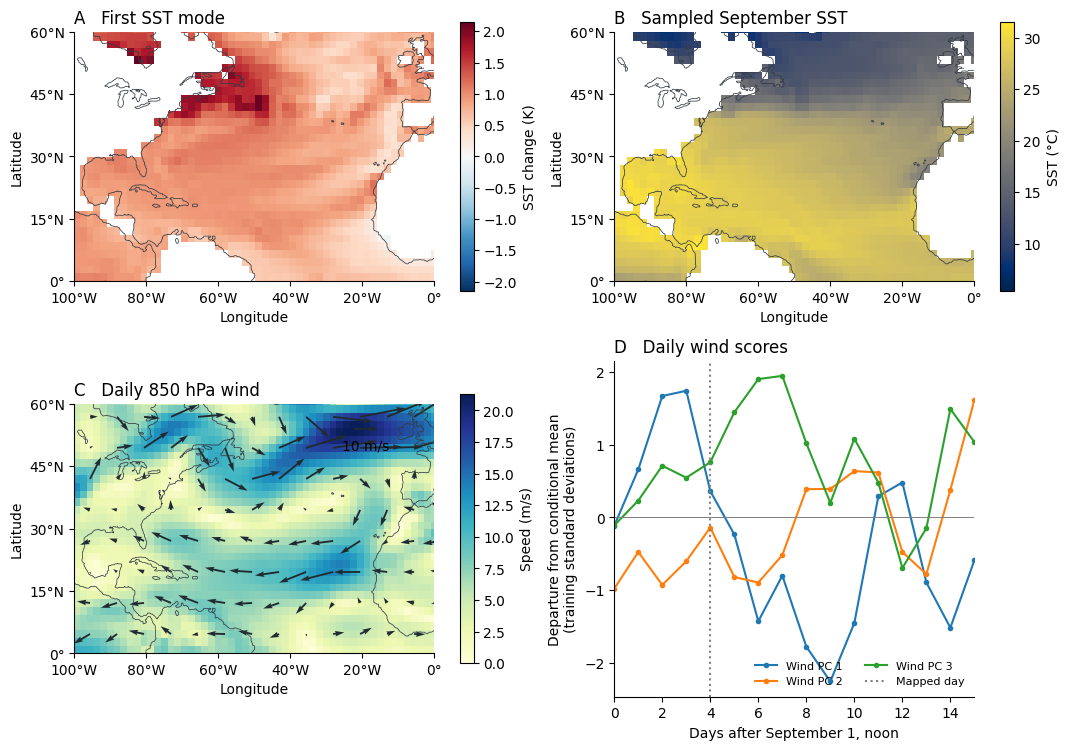

In [6]:
from matplotlib.ticker import FuncFormatter
_, _, _, land, _ = geography()
coast_x = np.linspace(-100, 0, 501)
coast_y = np.linspace(0, 60, 301)
land_fraction = land(coast_x + 360, coast_y).T

def basin_map(ax):
    ax.contour(coast_x, coast_y, land_fraction, levels=[0.5], colors="#333b44", linewidths=0.55)
    ax.set(xlim=(-100, 0), ylim=(0, 60), xlabel="Longitude", ylabel="Latitude")
    ax.set_xticks([-100, -80, -60, -40, -20, 0])
    ax.set_yticks([0, 15, 30, 45, 60])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):g}°W" if x else "0°"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}°N" if y else "0°"))
    ax.set_aspect(1 / np.cos(np.deg2rad(30)))

sst = model.rep.blocks["sst"]
score = np.zeros((1, len(sst.variance)))
score[0, 0] = np.sqrt(sst.variance[0])
pattern = (sst.inverse(score) - sst.inverse(0 * score))[0, 0]
x, y = demo.lon.values - 360, demo.lat.values
day = 4     # elapsed time since September 1 at noon
wind = demo.wind.sel(t_seconds=day * 86400)
u, v = (wind.sel(component=k).values for k in ("u850", "v850"))
fig, axs = plt.subplots(2, 2, figsize=(10.6, 7.6), layout="constrained")
peak = np.nanmax(np.abs(pattern))
panels = [(axs[0, 0], pattern, "RdBu_r", -peak, peak, "A   First SST mode", "SST change (K)"),
          (axs[0, 1], demo.sst.values - 273.15, "cividis", None, None, "B   Sampled September SST", "SST (°C)"),
          (axs[1, 0], np.hypot(u, v), "YlGnBu", 0, None, "C   Daily 850 hPa wind", "Speed (m/s)")]
for ax, field, cmap, low, high, title, units in panels:
    im = ax.pcolormesh(x, y, field, cmap=cmap, vmin=low, vmax=high, shading="auto")
    basin_map(ax)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=.8, label=units)
q = axs[1, 0].quiver(x[::4], y[::4], u[::4, ::4], v[::4, ::4], color="#202b31", scale=145)
axs[1, 0].quiverkey(q, .81, .90, 10, "10 m/s", coordinates="axes", labelpos="S")
ax = axs[1, 1]
elapsed = demo.t_seconds.values / 86400
for k in range(3):
    anomaly = (scores[:, k] - demo.conditional_wind_pc.values[k]) / np.sqrt(model.rep.blocks["wind"].variance[k])
    ax.plot(elapsed, anomaly, marker=".", label=f"Wind PC {k+1}")
ax.axhline(0, color="0.5", lw=.7)
ax.axvline(day, color="0.5", ls=":", label="Mapped day")
ax.set(title="D   Daily wind scores", xlabel="Days after September 1, noon",
       ylabel="Departure from conditional mean\n(training standard deviations)", xlim=(0, DAYS))
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.savefig(out / "eof_lim.png")
plt.show()

## 3 · Release the same disturbances into two weather systems

Coupled FAST moves each disturbance with intensity-dependent steering and beta drift. Potential intensity, moisture, vertical wind shear, ocean mixing and land conditions enter the intensity calculation. Random candidate locations are area-uniform in the project's seeding rectangle. FAST screens ocean location, latitude, potential intensity and ventilation. The project counts a TC when the two-day axisymmetric wind reaches 6.5 m/s, its peak reaches 15 m/s and the peak surface wind reaches 18 m/s. A landfall requires an accepted TC and an hourly sea-to-land crossing with surface wind at least 18 m/s. Failed seeds stay in the denominator. [FAST physics and source](https://github.com/linjonathan/tropical_cyclone_risk/tree/a540a1ed86b121f7244557edb691b40561b81939) · [Seeding and classification](../src/tc_emulator/tc_adapter.py)

Each event gets an independent seed panel, one thermodynamic background and one conditional mean wind. Both drivers receive identical seed positions, initial intensities and filter draws. The Fourier driver receives the LIM's exact zero-lag, four-component grid-point covariance at the selected warming. It then uses the native 15-harmonic generator and draws phases separately for each disturbance. The LIM driver shares one spatially varying daily realization across disturbances. The comparison therefore includes spatial coherence, temporal evolution and the choice of sharing weather across seeds. [Covariance calculation and paired integrations](tc_benchmark.py)

The 15-day window begins on September 1. The historical panels sample eight Septembers, spaced five years apart. The future panels sample independent backgrounds and winds at one 2050 warming level. The counts measure outcomes per attempted disturbance. An annual storm count would require a separate calibration of seeding exposure.

In [7]:
# run_pair calls event(...) and tracks(...) for each driver and returns hourly tracks.
historical = [(weights, "Historical", i, y, float(warming.loc[y]), seed, seeds_per_event)
              for i, y in enumerate(historical_years)]
future = [(weights, "Future", i, future_year, g_future, seed, seeds_per_event)
          for i in range(future_events)]
cases = historical + future
started = perf_counter()
if workers == 1:
    results = [run_pair(case) for case in cases]
else:
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as pool:
        results = list(pool.map(run_pair, cases))
wall_seconds = perf_counter() - started
paths = xr.concat([p for p, _, _ in results], dim="case", combine_attrs="drop")
attempts = pd.concat([a for _, a, _ in results], ignore_index=True)
times = pd.DataFrame([t for _, _, ts in results for t in ts])
assert len(attempts) == len(cases) * seeds_per_event * len(METHODS)
paired = attempts.set_index(["case", "method", "seed_id"]).sort_index()
seed_columns = ["lon", "lat", "v_init", "filter_draw", "offset_s"]
pd.testing.assert_frame_equal(paired.xs(METHODS[0], level="method")[seed_columns],
                              paired.xs(METHODS[1], level="method")[seed_columns])
assert (attempts.landfall <= attempts.tc).all() and (attempts.tc <= attempts.integrated).all()
assert paths.sizes["elapsed_s"] == 24 * DAYS + 1
for method in METHODS:
    for case_id, group in attempts[attempts.method == method].groupby("case"):
        track = paths.vmax.sel({"method": method, "case": case_id})
        np.testing.assert_array_equal(np.isfinite(track).any("elapsed_s"), group.sort_values("seed_id").integrated)
paths.attrs.update(title="North Atlantic September paired Coupled FAST trajectories",
    month=MONTH, duration_days=DAYS, weather_model=model.meta["id"], seed=seed,
    forcing="FaIR 2.2.4 SSP2-4.5, calibration 1.4.1 configuration 2451",
    event_origin="September 1 at noon in the statistical month",
    outcomes="Join attempts.parquet on case, method and seed_id. Screened seeds have no track.")
for field, unit in {"storm_lon":"degrees_east", "storm_lat":"degrees_north",
                    "vmax":"m s-1", "deep_shear":"m s-1", "elapsed_s":"s", "warming_K":"K"}.items():
    paths[field].attrs["units"] = unit
paths.warming_K.attrs["long_name"] = "annual global temperature relative to 1850–1900"
attempts.to_parquet(out / "attempts.parquet", index=False)
paths.to_netcdf(out / "tracks.nc", encoding={v: {"zlib": True, "complevel": 2} for v in paths.data_vars})
times.to_csv(out / "event_timings.csv", index=False)
print(f"{len(attempts):,} seed attempts across both drivers; {attempts.integrated.sum()} "
      f"passed screening. {paths.sizes['elapsed_s']} possible hourly positions per integration.")

4,096 seed attempts across both drivers; 1632 passed screening. 361 possible hourly positions per integration.


## 4 · Benchmark storm formation, landfall and runtime

The table gives the full count at each stage. Peak wind is the median of the hourly maximum surface winds of **accepted storms** within their 15-day integration windows. A run can stop earlier at dissipation or basin exit. For the paired differences we resample entire event pairs 5,000 times, leaving disturbances that share weather together. The intervals describe sampling variation across these few panels.

Sections 5–6 compare both generators with an MPI daily-wind replay on eight held-out members. To explore sampling in the smaller experiment here, increase `seeds_per_event` to draw more disturbances in the same environments, or `future_events` to draw additional environments. [2050 benchmark design](../reports/mpi2050/design.json)

In [8]:
group = attempts.groupby(["period", "method"], sort=False)
summary = group.agg(events=("case", "nunique"), attempts=("seed_id", "size"),
                    integrated=("integrated", "sum"), TCs=("tc", "sum"), landfalls=("landfall", "sum"))
summary["TC_per_100_attempts"] = 100 * summary.TCs / summary.attempts
summary["landfalls_per_100_attempts"] = 100 * summary.landfalls / summary.attempts
summary["median_peak_wind_ms"] = attempts[attempts.tc].groupby(["period", "method"]).lmi.median()
summary = summary.reindex(pd.MultiIndex.from_product([["Historical", "Future"], METHODS], names=summary.index.names))
summary.to_csv(out / "tc_counts.csv")
display(summary.round(2))
deltas = paired_rates(attempts, seed)
deltas.to_csv(out / "paired_differences.csv", index=False)
display(deltas.round(2))
timing = times.groupby("method").seconds.sum().to_frame("summed_track_call_s")
timing["attempts"] = attempts.groupby("method").size()
timing["attempts_per_solver_s"] = timing.attempts / timing.summed_track_call_s
display(timing.round(2))
print(f"FaIR setup + climate integration: {fair_seconds:.2f} s. Full paired panel wall time: {wall_seconds:.1f} s "
      f"({workers} processes, one BLAS thread each).")
timing.to_csv(out / "solver_timing.csv")
_ = (out / "run.json").write_text(json.dumps(dict(seed=seed, history_years=historical_years, future_year=future_year,
    future_g_K=g_future, baseline="1850–1900", fair_config=config_id, fair_s=fair_seconds, panel_wall_s=wall_seconds,
    weather_model=model.meta["id"], period_days=DAYS, seeds_per_event=seeds_per_event,
    future_events=future_events, workers=workers, cpu_arch=platform.machine(), python=platform.python_version(),
    packages={k:version(k) for k in ("fair", "numpy", "scipy", "pandas", "xarray", "torch")}), indent=2) + "\n")

events  attempts  integrated  TCs  landfalls  \
period     method                                                         
Historical Pure LIM             8      1024         420   27         18   
           Native Fourier       8      1024         414   31         23   
Future     Pure LIM             8      1024         409   32         29   
           Native Fourier       8      1024         389   22         16   

                           TC_per_100_attempts  landfalls_per_100_attempts  \
period     method                                                            
Historical Pure LIM                       2.64                        1.76   
           Native Fourier                 3.03                        2.25   
Future     Pure LIM                       3.12                        2.83   
           Native Fourier                 2.15                        1.56   

                           median_peak_wind_ms  
period     method                               
Historical Pure LIM                      38.54  
           Native Fourier                35.02  
Future     Pure LIM                      37.54  
           Native Fourier                35.38

,period,outcome,paired_events,lim_minus_fourier_pp,event_boot_low_pp,event_boot_high_pp
0,Historical,tc,8,-0.39,-1.76,1.66
1,Historical,landfall,8,-0.49,-2.05,1.76
2,Future,tc,8,0.98,-0.29,2.25
3,Future,landfall,8,1.27,0.20,2.34


,summed_track_call_s,attempts,attempts_per_solver_s
method,,,
Native Fourier,32.06,2048,63.87
Pure LIM,21.97,2048,93.22


FaIR setup + climate integration: 0.54 s. Full paired panel wall time: 22.1 s (3 processes, one BLAS thread each).


Solver seconds sum time inside the track calls across workers and include screening, integration, and recording hourly diagnostics. They exclude background generation and construction of the Fourier provider. Panel wall time also includes those operations and process startup. Each driver can integrate a different number of disturbances, which affects throughput.

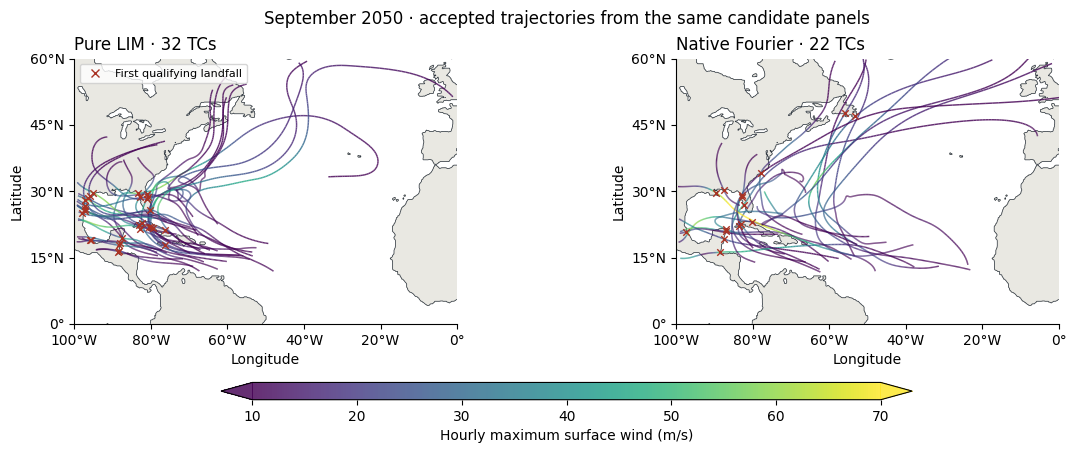

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
norm = Normalize(10, 70, clip=True)
for ax, method in zip(axs, METHODS):
    ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#e9e8e2"])
    basin_map(ax)
    subset = attempts[(attempts.period == "Future") & (attempts.method == method) & attempts.tc]
    segments, speeds = [], []
    for row in subset.itertuples(index=False):
        t = paths.sel({"case": row.case, "method": method, "seed_id": row.seed_id})
        ok = np.isfinite(t.vmax.values)
        xy = np.column_stack((t.storm_lon.values[ok] - 360, t.storm_lat.values[ok]))
        segments.extend(np.stack((xy[:-1], xy[1:]), axis=1))
        speeds.extend((t.vmax.values[ok][:-1] + t.vmax.values[ok][1:]) / 2)
    lines = LineCollection(segments, cmap="viridis", norm=norm, linewidths=1.05, alpha=.82)
    lines.set_array(np.asarray(speeds))
    ax.add_collection(lines)
    hits = subset[subset.landfall]
    ax.scatter(hits.landfall_lon - 360, hits.landfall_lat, marker="x", s=22,
               color="#a93324", linewidth=1, zorder=4)
    ax.set_title(f"{method} · {len(subset)} TCs")
fig.suptitle(f"September {future_year} · accepted trajectories from the same candidate panels")
fig.colorbar(lines, ax=axs, location="bottom", shrink=.58, aspect=40, label="Hourly maximum surface wind (m/s)",
             extend="both")
axs[0].legend(handles=[Line2D([], [], linestyle="", marker="x", color="#a93324",
                              label="First qualifying landfall")], loc="upper left", fontsize=8)
fig.savefig(out / "tc_tracks.png")
plt.show()

An individual trajectory helps explain why switching the weather driver changes the counts. Take the first future case and seed ID (in numerical order) that qualifies as a TC with both drivers. Both tracks begin with the same initial location and intensity. As their environmental winds and positions diverge, the vertical shear along each path can also change. The monthly ocean background is fixed in both runs.

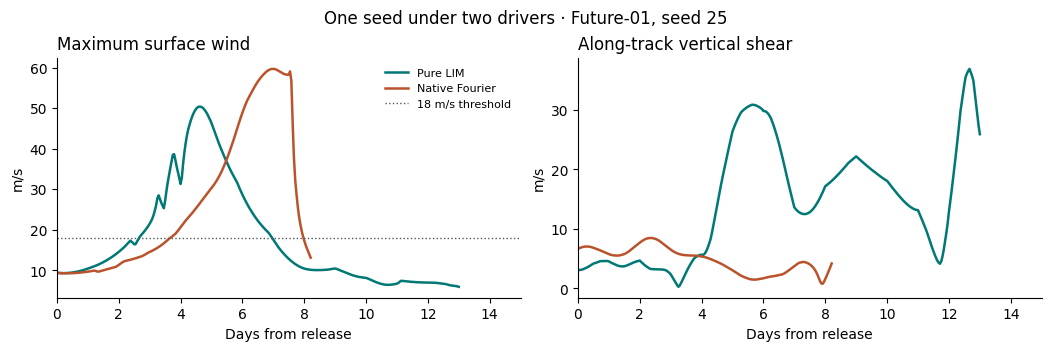

In [10]:
future_rows = attempts[attempts.period == "Future"]
qualified = future_rows.pivot(index=["case", "seed_id"], columns="method", values="tc").all(axis=1)
integrated = future_rows.pivot(index=["case", "seed_id"], columns="method", values="integrated").all(axis=1)
pairs = qualified[qualified].index if qualified.any() else integrated[integrated].index
if len(pairs):
    case_id, seed_id = pairs[0]
    fig, axs = plt.subplots(1, 2, figsize=(10.4, 3.4), layout="constrained")
    for method in METHODS:
        tr = paths.sel({"case": case_id, "method": method, "seed_id": seed_id})
        for ax, var, title in zip(axs, ["vmax", "deep_shear"], ["Maximum surface wind", "Along-track vertical shear"]):
            ax.plot(tr.elapsed_s / 86400, tr[var], color=colors[method], label=method, linewidth=1.8)
            ax.set(title=title, xlabel="Days from release", ylabel="m/s", xlim=(0, DAYS))
    axs[0].axhline(18, ls=":", color="#51575b", lw=1, label="18 m/s threshold")
    axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"One seed under two drivers · {case_id}, seed {seed_id}")
    fig.savefig(out / "storm_evolution.png")
    plt.show()
else:
    print("No future seed integrated under both drivers in this panel.")

## 5 · Replay September 2050 with MPI daily winds

What would the same disturbance do in weather actually produced by the climate model? The reference run feeds MPI-ESM1-2-LR's daily eastward and northward winds at 250 and 850 hPa into FAST. The other two runs use the same MPI monthly ocean and atmospheric fields and switch the wind generator. All three start from the same location and intensity and use the same screening draw. The tracks are synthetic FAST storms in the SSP2-4.5 model climate. [MPI-M SSP2-4.5 data, Wieners et al.](https://doi.org/10.22033/ESGF/CMIP6.6693) · [Input files and preprocessing](../reports/mpi2050/README.md)

For a reproducible example, take the first held-out member in the published split. Within that member, take the first weather draw, start date and seed ID in ascending order for which all three archived storms have a complete 48-hour window. The selection uses availability alone. Each driver's window starts at its own first six-hourly fix with wind of at least 18 m/s.

In [11]:
from benchmark_mpi2050 import (DESIGN, FOURIER, LIM, MPI, SEED as mpi_seed,
                               fourier_inputs, sampled_window, seed_panel)
from tc_benchmark import aligned_window
from tc_emulator.fourier_weather import NativeFourierWind, WindStatistics
from tc_emulator.tc_adapter import replay_event, tracks

mpi_report = root / "reports/mpi2050"
mpi_out = out / "mpi2050"
mpi_out.mkdir(exist_ok=True)
drivers = [MPI, LIM, FOURIER]
colors[MPI] = "#334355"
colors[LIM] = "#3563a0"
fixed_bg, fair_only = "MPI background", "FaIR warming only"
storm_key = ["protocol", "method", "member", "draw", "origin", "seed_id"]

mpi_year, mpi_month, duration = DESIGN["year"], DESIGN["month"], DESIGN["event_days"]
member = json.loads((root / "configs/annual_lim/members.json").read_text())["test"][0]
mpi_g = json.loads((mpi_report / "forcing.json").read_text())["warming_K"]
reference_file = data / "mpi_ssp245_r9_2050_09.nc"
expected = json.loads((mpi_report / "reproducibility.json").read_text())["reference_inputs"][member]
assert hashlib.sha256(reference_file.read_bytes()).hexdigest() == expected
with xr.open_dataset(reference_file, decode_times=False) as ds:
    mpi_fields = ds.load()
assert (mpi_fields.attrs["member"], mpi_fields.attrs["experiment"],
        mpi_fields.attrs["year"], mpi_fields.attrs["month"]) == (member, "ssp245", mpi_year, mpi_month)

mpi_attempts = pd.read_parquet(mpi_report / "attempts.parquet")
same_background = mpi_attempts[mpi_attempts.protocol.isin(["Reference", fixed_bg]) &
                               mpi_attempts.method.isin(drivers)]
available = (same_background.loc[same_background.member.eq(member) & same_background.tc]
             .pivot(index=["draw", "origin", "seed_id"], columns="method", values="displacement_48h_km")
             .reindex(columns=drivers).dropna().sort_index())
draw, origin, example_id = map(int, available.index[0])
seeds = seed_panel(member, draw, origin)
one_seed = seeds.loc[seeds.seed_id.eq(example_id)]
print(f"{member}, September {origin}, {mpi_year}, noon UTC · draw {draw}, seed {example_id}")
print(f"MPI warming {mpi_g:+.3f} K · FaIR warming for the same year {warming.loc[mpi_year]:+.3f} K")

r9i1p1f1, September 5, 2050, noon UTC · draw 1, seed 74
MPI warming +1.799 K · FaIR warming for the same year +1.813 K


In [12]:
# One generator gets MPI's daily wind directly. LIM and Fourier share the predicted
# wind mean and pointwise covariance specification conditional on MPI's monthly background.
mpi_env = replay_event(mpi_fields, duration, origin_day=origin)
ident = f"{member}/{draw}"
sampled_month = event(weights, mpi_month, mpi_year, mpi_g, 30, mpi_seed, ident, draw, observed=mpi_fields)
lim_env = sampled_window(sampled_month, origin, duration)
mpi_model, unit_cov = fourier_inputs(weights)
mean_wind = mpi_model.rep.blocks["wind"].inverse(sampled_month.conditional_wind_pc.values[None])[0]
fourier_stats = WindStatistics(mean_wind, unit_cov * mpi_model.cal.amplitude(mpi_g)**2)
fourier_driver = NativeFourierWind(fourier_stats, mpi_fields.lon.values, mpi_fields.lat.values,
                                   mpi_seed, ("SSP245", mpi_year, member), draw,
                                   independent_storms=True, origin_day=origin)
np.testing.assert_array_equal(mpi_env.vpot, lim_env.vpot)

live_paths, live_windows, example_rows = {}, {}, []
for driver, environment, wind_driver in [(MPI, mpi_env, None), (LIM, lim_env, None),
                                          (FOURIER, lim_env, fourier_driver)]:
    hourly, outcome = tracks(environment, one_seed, duration, wind_provider=wind_driver)
    t = hourly.sel(seed_id=example_id).isel(elapsed_s=slice(None, None, 6))
    hours = t.elapsed_s.values / 3600
    v = t.vmax.values
    window = aligned_window(t.storm_lon.values, t.storm_lat.values, v, hours, np.isfinite(v))
    live_paths[driver], live_windows[driver] = t, window
    start_h, distance = (hours[window[0]], window[2]) if window is not None else (np.nan, np.nan)
    example_rows.append([driver, outcome.tc.item(), start_h, distance,
                         available.loc[(draw, origin, example_id), driver]])
display(pd.DataFrame(example_rows, columns=["Wind driver", "Accepted TC", "Window starts (h)",
                                            "Live displacement (km)", "Archived displacement (km)"])
        .set_index("Wind driver").round(1))

,Accepted TC,Window starts (h),Live displacement (km),Archived displacement (km)
Wind driver,,,,
MPI daily,True,144.0,999.0,999.0
Pure LIM,True,66.0,1372.4,1372.4
Native Fourier,True,270.0,1449.5,1449.5


### A common release and the full track ensemble

Each basin map below shows the six-hourly positions of **every accepted storm** under that driver, from seed release until the end of integration. The panels use the same eight held-out members, September 5 and 14 starts, four seed panels per member and start, and 256 proposed disturbances per panel. A driver can turn a different subset of those 16,384 disturbances into storms.

The enlarged map follows the common seed just integrated. The dotted section connects the release to the first qualifying fix. The solid section covers the following 48 hours. A circle marks the start of that window and a square marks its end. The wind that drives FAST changes the timing as well as the direction of travel. [Stored six-hourly positions](../reports/mpi2050/tc_tracks_6h.parquet)

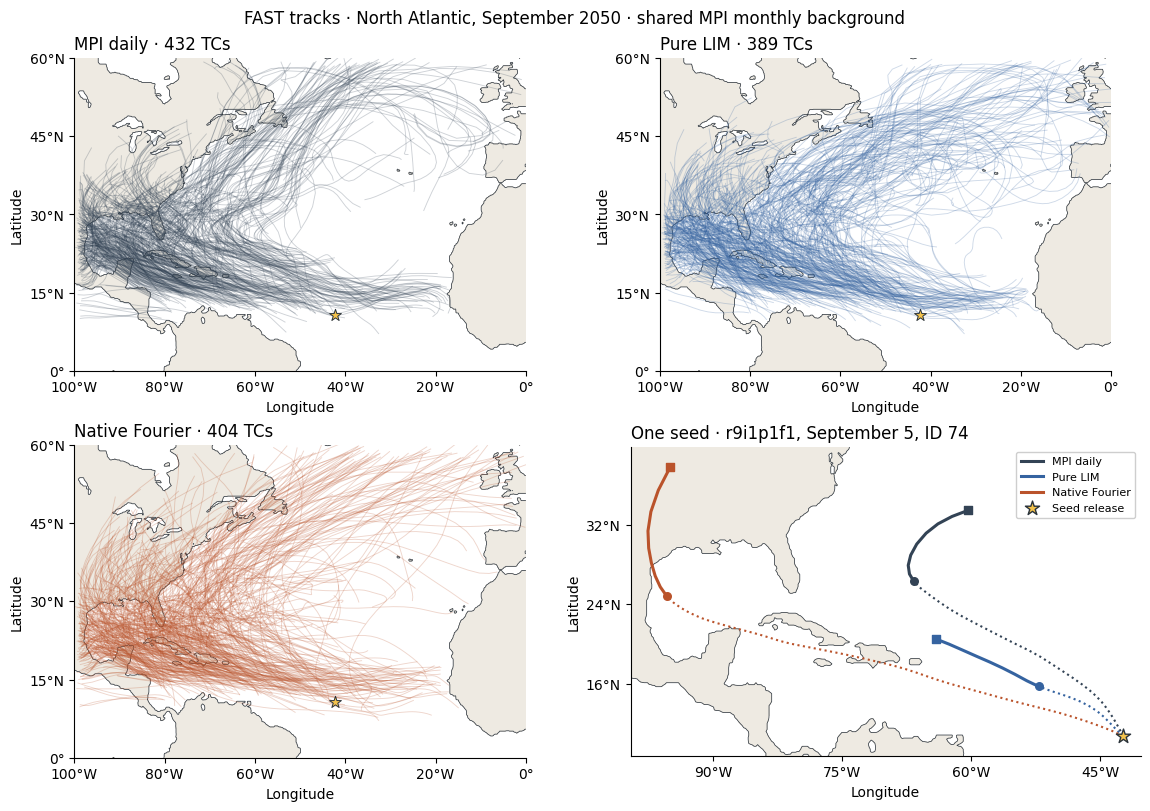

In [13]:
from matplotlib.ticker import MaxNLocator

fixes = pd.read_parquet(mpi_report / "tc_tracks_6h.parquet").sort_values(storm_key + ["elapsed_h"])
assert not fixes.duplicated(storm_key + ["elapsed_h"]).any()
assert np.isfinite(fixes[["lon_e", "lat_n", "vmax_ms"]].to_numpy()).all()
accepted = mpi_attempts.loc[mpi_attempts.tc].set_index(storm_key).sort_index()
track_ids = pd.MultiIndex.from_frame(fixes[storm_key].drop_duplicates())
pd.testing.assert_index_equal(track_ids, accepted.index)

fig, axs = plt.subplots(2, 2, figsize=(11.4, 8.0), layout="constrained")
for ax, driver in zip(axs.flat[:3], drivers):
    case_protocol = "Reference" if driver == MPI else fixed_bg
    group = fixes[fixes.protocol.eq(case_protocol) & fixes.method.eq(driver)]
    segments = [np.column_stack((track.lon_e.to_numpy() - 360, track.lat_n))
                for _, track in group.groupby(["member", "draw", "origin", "seed_id"], sort=False)]
    ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#eeeae2"])
    basin_map(ax)
    ax.add_collection(LineCollection(segments, colors=colors[driver], linewidths=.65, alpha=.24))
    ax.scatter(one_seed.lon - 360, one_seed.lat, marker="*", s=80, c="#f4c34c",
               edgecolors="#29323a", linewidths=.7, zorder=4)
    ax.set_title(f"{driver} · {len(segments)} TCs")

ax = axs[1, 1]
ax.contourf(coast_x, coast_y, land_fraction, levels=[.5, 1.1], colors=["#eeeae2"])
basin_map(ax)
x0, y0 = float(one_seed.lon.iloc[0] - 360), float(one_seed.lat.iloc[0])
shown = [np.array([[x0, y0]])]
for driver in drivers:
    t, window = live_paths[driver], live_windows[driver]
    xy = np.column_stack((t.storm_lon.values - 360, t.storm_lat.values))
    if window is None:
        xy = xy[np.isfinite(xy).all(axis=1)]
        ax.plot(*xy.T, color=colors[driver], ls=":", label=f"{driver} (incomplete)")
    else:
        begin = window[0]
        xy = xy[:begin + 9]
        ax.plot(*xy[:begin + 1].T, color=colors[driver], ls=":", lw=1.5)
        ax.plot(*xy[begin:].T, color=colors[driver], lw=2.2, label=driver)
        ax.scatter(*xy[begin], color=colors[driver], s=30, marker="o", zorder=4)
        ax.scatter(*xy[-1], color=colors[driver], s=30, marker="s", zorder=4)
    shown.append(xy)
ax.scatter(x0, y0, marker="*", s=115, c="#f4c34c", edgecolors="#29323a", zorder=5, label="Seed release")
extent = np.concatenate(shown)
ax.set(xlim=(extent[:, 0].min()-2, extent[:, 0].max()+2), ylim=(extent[:, 1].min()-2, extent[:, 1].max()+2))
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(5))
ax.set_title(f"One seed · {member}, September {origin}, ID {example_id}")
ax.legend(frameon=True, framealpha=.95, fontsize=8, loc="best")
fig.suptitle("FAST tracks · North Atlantic, September 2050 · shared MPI monthly background")
fig.savefig(mpi_out / "mpi_track_maps.png")
plt.show()

## 6 · How far do September storms move in 48 hours?

For each accepted storm, locate the first six-hourly tropical fix at or above 18 m/s. A storm enters the displacement sample when that fix and the next eight form a complete, continuous 48-hour window inside the study region. Measure the great-circle distance between the first and last position. Formation and landfall rates still use all proposed disturbances.

The left panel gives both LIM versions the same monthly MPI fields. The right panel supplies only FaIR warming and each version samples its own background. The fixed native Fourier control uses v1 wind moments. Both panels use the same MPI-driven storms. At distance $x$, the vertical coordinate $F(x)$ is the fraction of eligible storms with displacement at most $x$. The area between two curves, $W_1=\int |F_{\mathrm{model}}(x)-F_{\mathrm{MPI}}(x)|\,dx$, is the distributional error in kilometres. Smaller is closer to MPI. Each legend shows how many storms contributed.

In [14]:
def check_48h_tracks(track_rows, attempt_rows, keys):
    """Rebuild each accepted storm's 48-hour endpoint separation from its six-hourly fixes."""
    values = []
    for identity, track in track_rows.sort_values(keys + ["elapsed_h"]).groupby(keys, sort=False):
        hours = track.elapsed_h.to_numpy()
        assert hours[0] == 0 and np.all(np.diff(hours) == 6)
        window = aligned_window(track.lon_e.to_numpy(), track.lat_n.to_numpy(), track.vmax_ms.to_numpy(),
                                hours, np.ones(len(track), dtype=bool))
        values.append((*identity, window[2] if window is not None else np.nan))
    rebuilt = pd.DataFrame(values, columns=[*keys, "km"]).set_index(keys).sort_index()
    archived = attempt_rows.loc[attempt_rows.tc].set_index(keys).sort_index()
    pd.testing.assert_index_equal(rebuilt.index, archived.index)
    np.testing.assert_allclose(rebuilt.km, archived.displacement_48h_km, atol=0.005, rtol=0, equal_nan=True)


def check_disturbances(reference, other, keys):
    """Check the seed location, initial intensity and genesis random draw for every proposed storm."""
    columns = keys + ["lon", "lat", "v_init", "filter_draw"]
    assert not reference.duplicated(keys).any() and not other.duplicated(keys).any()
    pd.testing.assert_frame_equal(reference.sort_values(keys)[columns].reset_index(drop=True),
                                  other.sort_values(keys)[columns].reset_index(drop=True),
                                  check_exact=True, check_dtype=False)


study = root / "reports" / "annual_refinement"
study_data = study / "data"
september_conditions = {fixed_bg: "MPI monthly background", fair_only: "FaIR warming only"}
research_attempts = pd.read_parquet(study_data / "september_mpi2050_attempts.parquet")
research_fixes = pd.read_parquet(study_data / "september_mpi2050_tc_tracks_6h.parquet")
select_research = lambda frame: frame.method.eq(LIM) & frame.protocol.isin(september_conditions)
check_48h_tracks(fixes, mpi_attempts, storm_key)
check_48h_tracks(research_fixes[select_research(research_fixes)],
                 research_attempts[select_research(research_attempts)], storm_key)

v1_label, research_label, fourier_label = "Published LIM (v1)", "Research LIM", "Native Fourier (v1 moments)"
release_rows = mpi_attempts[mpi_attempts.method.isin(drivers)].copy()
release_rows["driver"] = release_rows.method.map({MPI: MPI, LIM: v1_label, FOURIER: fourier_label})
september = pd.concat([release_rows, research_attempts[select_research(research_attempts)]
                       .assign(driver=research_label)], ignore_index=True)
seed_key = ["member", "draw", "origin", "seed_id"]
reference_seeds = september[september.driver == MPI]
for condition in september_conditions:
    for driver in [v1_label, research_label, fourier_label]:
        check_disturbances(reference_seeds, september[(september.driver == driver) &
                                                      (september.protocol == condition)], seed_key)
print(f"{len(reference_seeds):,} matched proposals per September driver and input condition. "
      "Both LIM versions' 48-hour samples match their six-hourly tracks.")

16,384 matched proposals per September driver and input condition. Both LIM versions' 48-hour samples match their six-hourly tracks.


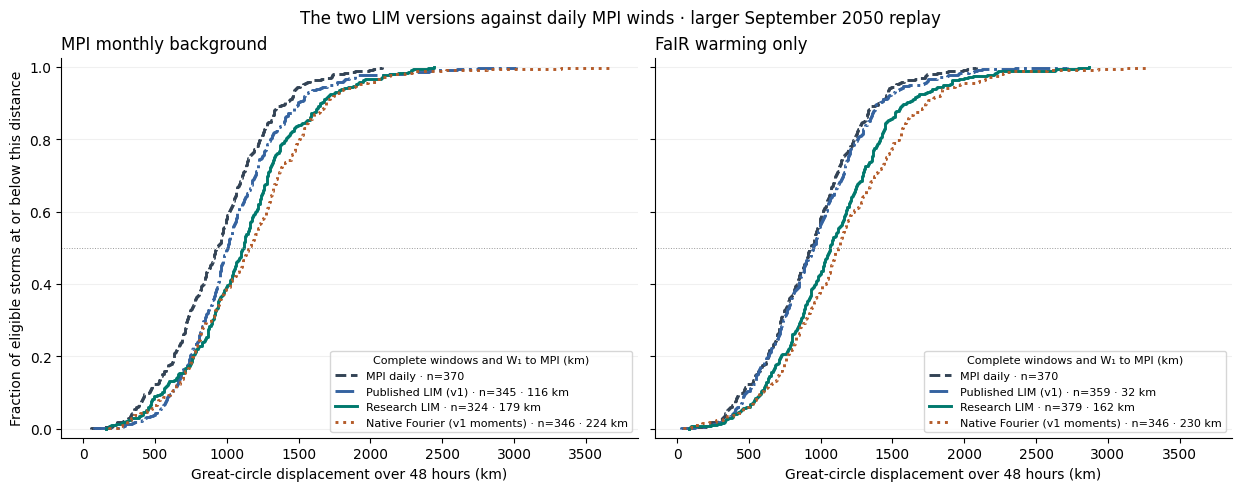

Attempts  TCs  TC landfalls  \
Inputs            Wind driver                                                
Reference         MPI daily                       16384  432           337   
MPI background    Published LIM (v1)              16384  389           281   
                  Research LIM                    16384  392           289   
                  Native Fourier (v1 moments)     16384  404           313   
FaIR warming only Published LIM (v1)              16384  399           283   
                  Research LIM                    16384  431           299   
                  Native Fourier (v1 moments)     16384  400           303   

                                               48 h windows  \
Inputs            Wind driver                                 
Reference         MPI daily                             370   
MPI background    Published LIM (v1)                    345   
                  Research LIM                          324   
                  Native Fourier (v1 moments)           346   
FaIR warming only Published LIM (v1)                    359   
                  Research LIM                          379   
                  Native Fourier (v1 moments)           346   

                                               Median displacement (km)  \
Inputs            Wind driver                                             
Reference         MPI daily                                       925.6   
MPI background    Published LIM (v1)                             1007.2   
                  Research LIM                                   1115.7   
                  Native Fourier (v1 moments)                    1156.0   
FaIR warming only Published LIM (v1)                              947.0   
                  Research LIM                                   1065.5   
                  Native Fourier (v1 moments)                    1125.2   

                                               W1 to MPI (km)  
Inputs            Wind driver                                  
Reference         MPI daily                               0.0  
MPI background    Published LIM (v1)                    116.0  
                  Research LIM                          179.1  
                  Native Fourier (v1 moments)           224.3  
FaIR warming only Published LIM (v1)                     31.8  
                  Research LIM                          161.7  
                  Native Fourier (v1 moments)           229.8

In [15]:
from scipy.stats import wasserstein_distance

version_colors = {MPI: "#334355", v1_label: "#3563a0", research_label: "#00796d", fourier_label: "#b45b29"}
version_styles = {MPI: "--", v1_label: "-.", research_label: "-", fourier_label: ":"}


def eligible_km(frame):
    distance = frame.loc[frame.tc, "displacement_48h_km"].to_numpy()
    return distance[np.isfinite(distance)]


reference_km = eligible_km(reference_seeds)
september_scores = pd.read_csv(study_data / "paired_mpi2050.csv")
score_labels = {v1_label: "Published LIM", research_label: "Research LIM", fourier_label: "Fixed native Fourier"}
fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.8), sharex=True, sharey=True, layout="constrained")
table = []
for ax, (condition, label) in zip(axes, september_conditions.items()):
    for driver in (MPI, v1_label, research_label, fourier_label):
        protocol = "Reference" if driver == MPI else condition
        group = september[(september.protocol == protocol) & (september.driver == driver)]
        km = eligible_km(group)
        w1 = wasserstein_distance(reference_km, km)
        label_text = f"{driver} · n={len(km)}" + (f" · {w1:.0f} km" if driver != MPI else "")
        ax.ecdf(km, color=version_colors[driver], ls=version_styles[driver], lw=2.1, label=label_text)
        if driver != MPI:
            archived = september_scores[(september_scores.protocol == condition) &
                                        (september_scores.driver == score_labels[driver]) &
                                        (september_scores.metric == "displacement_48h_km")]
            np.testing.assert_allclose(w1, archived.error.item(), atol=0.005, rtol=0)
        if driver != MPI or condition == fixed_bg:
            table.append([protocol, driver, len(group), int(group.tc.sum()), int(group.landfall.sum()),
                          len(km), np.median(km), w1])
    ax.set(title=label, xlabel="Great-circle displacement over 48 hours (km)", ylim=(-.025, 1.025))
    ax.axhline(.5, lw=.7, color=".6", ls=":")
    ax.grid(axis="y", alpha=.18)
    ax.legend(loc="lower right", fontsize=8, title="Complete windows and W₁ to MPI (km)", title_fontsize=8)
axes[0].set_ylabel("Fraction of eligible storms at or below this distance")
fig.suptitle("The two LIM versions against daily MPI winds · larger September 2050 replay")
fig.savefig(mpi_out / "mpi_displacement_cdf.png")
plt.show()

storm_stats = pd.DataFrame(table, columns=["Inputs", "Wind driver", "Attempts", "TCs", "TC landfalls",
                                           "48 h windows", "Median displacement (km)", "W1 to MPI (km)"])
storm_stats.to_csv(mpi_out / "storm_statistics.csv", index=False)
display(storm_stats.set_index(["Inputs", "Wind driver"]).round(1))

### Paired uncertainty in the larger September replay

With the MPI monthly background, displacement W1 rises from **116.0 km for v1 to 179.1 km for Research**. The Research-minus-v1 difference is **+63.1 km**, with a paired 95% interval of **−14.8 to +126.3 km**. With FaIR warming alone the scores are **31.8 and 161.7 km**, a difference of **+129.9 km** (−37.4 to +156.7 km). The point estimates favour v1 in both conditions. The intervals span zero when the eight whole MPI members are resampled. [Paired comparisons for both LIMs and the Fourier controls](../reports/annual_refinement/data/paired_mpi2050.csv)

The following figure reproduces the published **v1 versus native Fourier** benchmark. Its wind panel uses $0.2\,\mathbf u_{250}+0.8\,\mathbf u_{850}$, subtracts the September mean and measures area-weighted variance of 1-, 5-, 10- and 15-day averages. FAST itself uses intensity-dependent weights. The three storm panels show Fourier error minus **v1** error, so a positive value favours v1. Formation and landfall errors are absolute differences from the MPI rate per 100 proposed seeds. The 5,000 bootstrap draws resample the same eight members for each driver. [Scoring code](score_mpi2050.py)

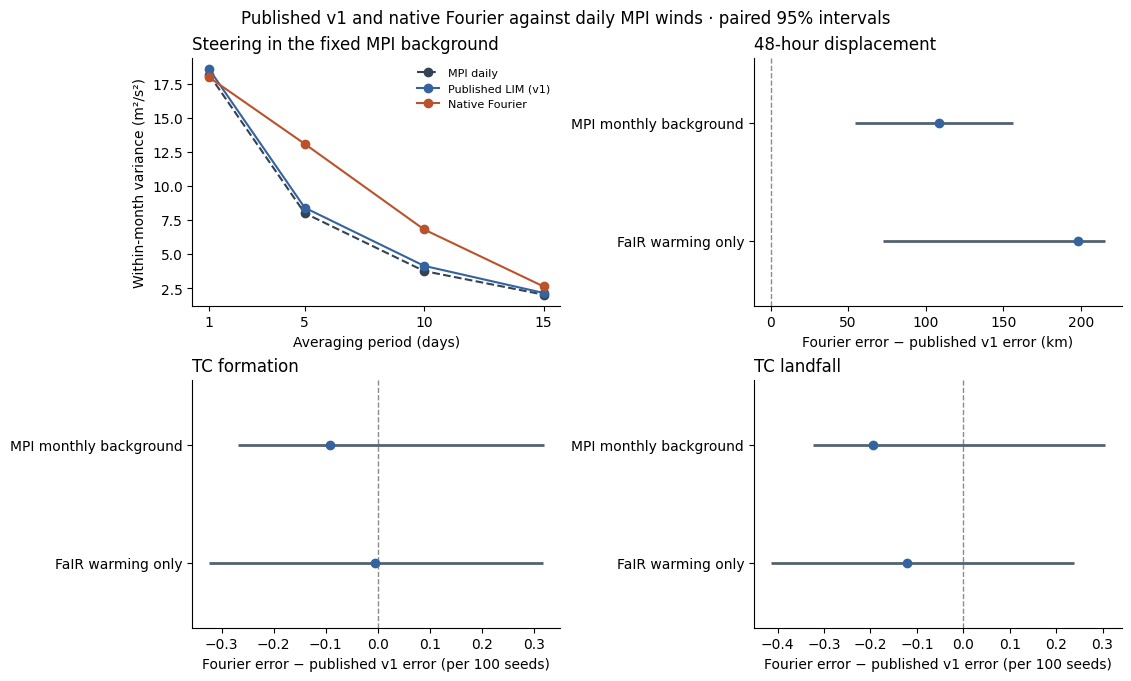

In [16]:
from score_mpi2050 import summarize

paired_scores, _, _ = summarize(mpi_report)  # Recompute rates, W1 distances and paired intervals.
scores_native = paired_scores[paired_scores.comparator.eq(FOURIER)].set_index(["protocol", "metric"])
for row in storm_stats.itertuples(index=False, name=None):
    protocol, driver, *_, w1 = row
    if driver in (v1_label, fourier_label):
        column = "lim_error" if driver == v1_label else "fourier_error"
        np.testing.assert_allclose(w1, scores_native.loc[(protocol, "displacement_48h_km"), column], atol=0.005, rtol=0)

fig, axs = plt.subplots(2, 2, figsize=(11.2, 6.7), layout="constrained")
ax = axs[0, 0]
days = [1, 5, 10, 15]
wind = scores_native.loc[fixed_bg].loc[[f"steering_{d}d" for d in days]]
for driver, col in zip(drivers, ["reference", "lim", "fourier"]):
    ax.plot(days, wind[col], marker="o", color=colors[driver], ls="--" if driver == MPI else "-", label=v1_label if driver == LIM else driver)
ax.set(title="Steering in the fixed MPI background", xlabel="Averaging period (days)",
       ylabel="Within-month variance (m²/s²)", xticks=days)
ax.legend(frameon=False, fontsize=8)

metrics = [("displacement_48h_km", "48-hour displacement", "km"),
           ("tc_per_100", "TC formation", "per 100 seeds"),
           ("landfall_per_100", "TC landfall", "per 100 seeds")]
for ax, (metric, title, unit) in zip(axs.flat[1:], metrics):
    ax.axvline(0, color=".55", ls="--", lw=1)
    for i, condition in enumerate(september_conditions):
        r = scores_native.loc[(condition, metric)]
        ax.hlines(i, r.paired_low, r.paired_high, color="#526270", lw=2)
        ax.plot(r.advantage, i, "o", color=colors[LIM], ms=6)
    ax.set(title=title, xlabel=f"Fourier error − published v1 error ({unit})",
           yticks=[0, 1], yticklabels=list(september_conditions.values()), ylim=(1.55, -.55))
fig.suptitle("Published v1 and native Fourier against daily MPI winds · paired 95% intervals")
fig.savefig(mpi_out / "mpi_skill_intervals.png")
plt.show()

In this September replay, the **published v1 LIM** reduces displacement W1 relative to native Fourier by **108 km** with the MPI background (paired 95% interval **54–156 km**) and **198 km** with FaIR warming alone (**72–216 km**). MPI, FaIR–v1 LIM and FaIR–Fourier form **432, 399 and 400 storms** per 16,384 proposals. The formation and landfall intervals span zero. The following annual experiment uses a different disturbance panel. Its September sample is smaller. [September benchmark, protocols and additional controls](../reports/mpi2050/README.md)

## 7. Follow the 2050 comparison through all twelve months

The larger September experiment used four panels of 256 disturbances for each September 5 and 14 start per MPI member. This annual replay uses one panel of 96 disturbances for each day 5 and day 12 start in each of twelve months. That gives 1,536 proposals per month and 18,432 per driver for the year. The eight held-out members supply the same fixed monthly MPI backgrounds and the same proposed disturbances across drivers. The annual warming input is the SSP2-4.5 MPI ensemble's 2050 value.

The table distinguishes all accepted storms from the subset eligible for a 48-hour displacement. Lifetime peak wind uses the accepted storms. The native Fourier controls use either v1 or Research instantaneous wind moments. In the calendar figure, read the lower-left panel as **monthly displacement W1 error**. Higher means farther from the MPI distribution. Each point in that panel summarizes an entire month's displacement sample.

,TCs,48 h windows,TCs per 100 seeds,48 h displacement W1 (km),Lifetime peak wind W1 (m/s)
Driver,,,,,
MPI daily,120,103,0.65,0.00,0.00
Published LIM (v1),120,106,0.65,92.09,4.87
Research LIM,98,86,0.53,95.46,1.52
Native Fourier (v1 moments),84,69,0.46,221.80,2.03
Native Fourier (research moments),94,81,0.51,206.71,2.22


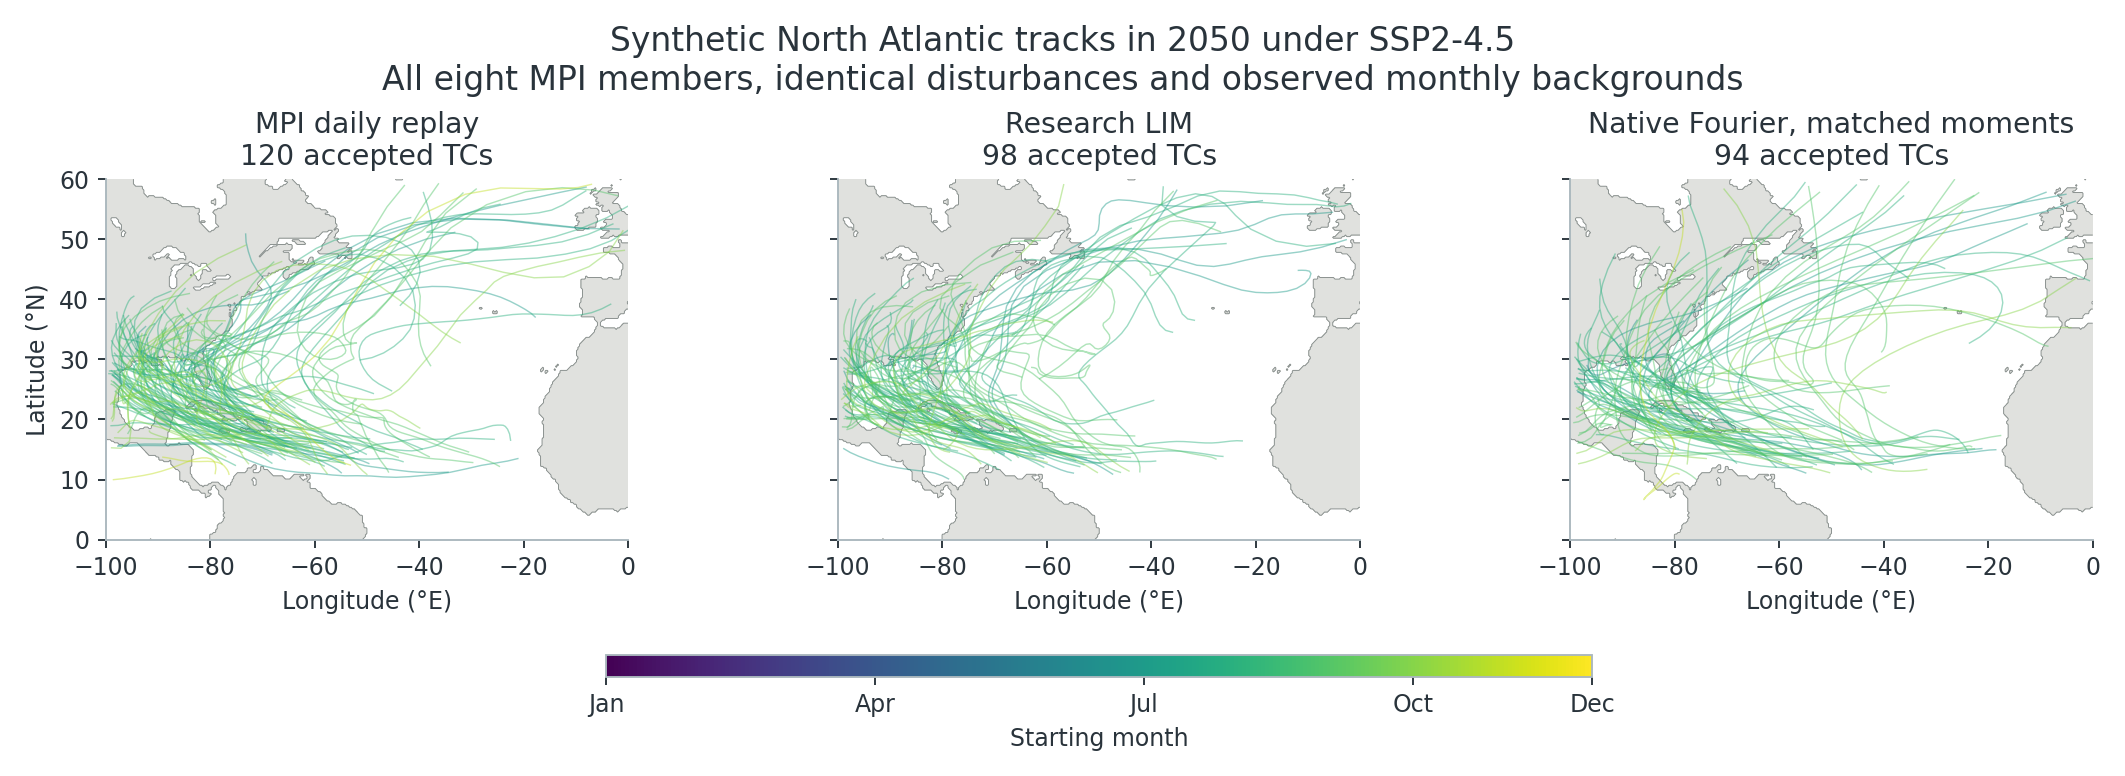

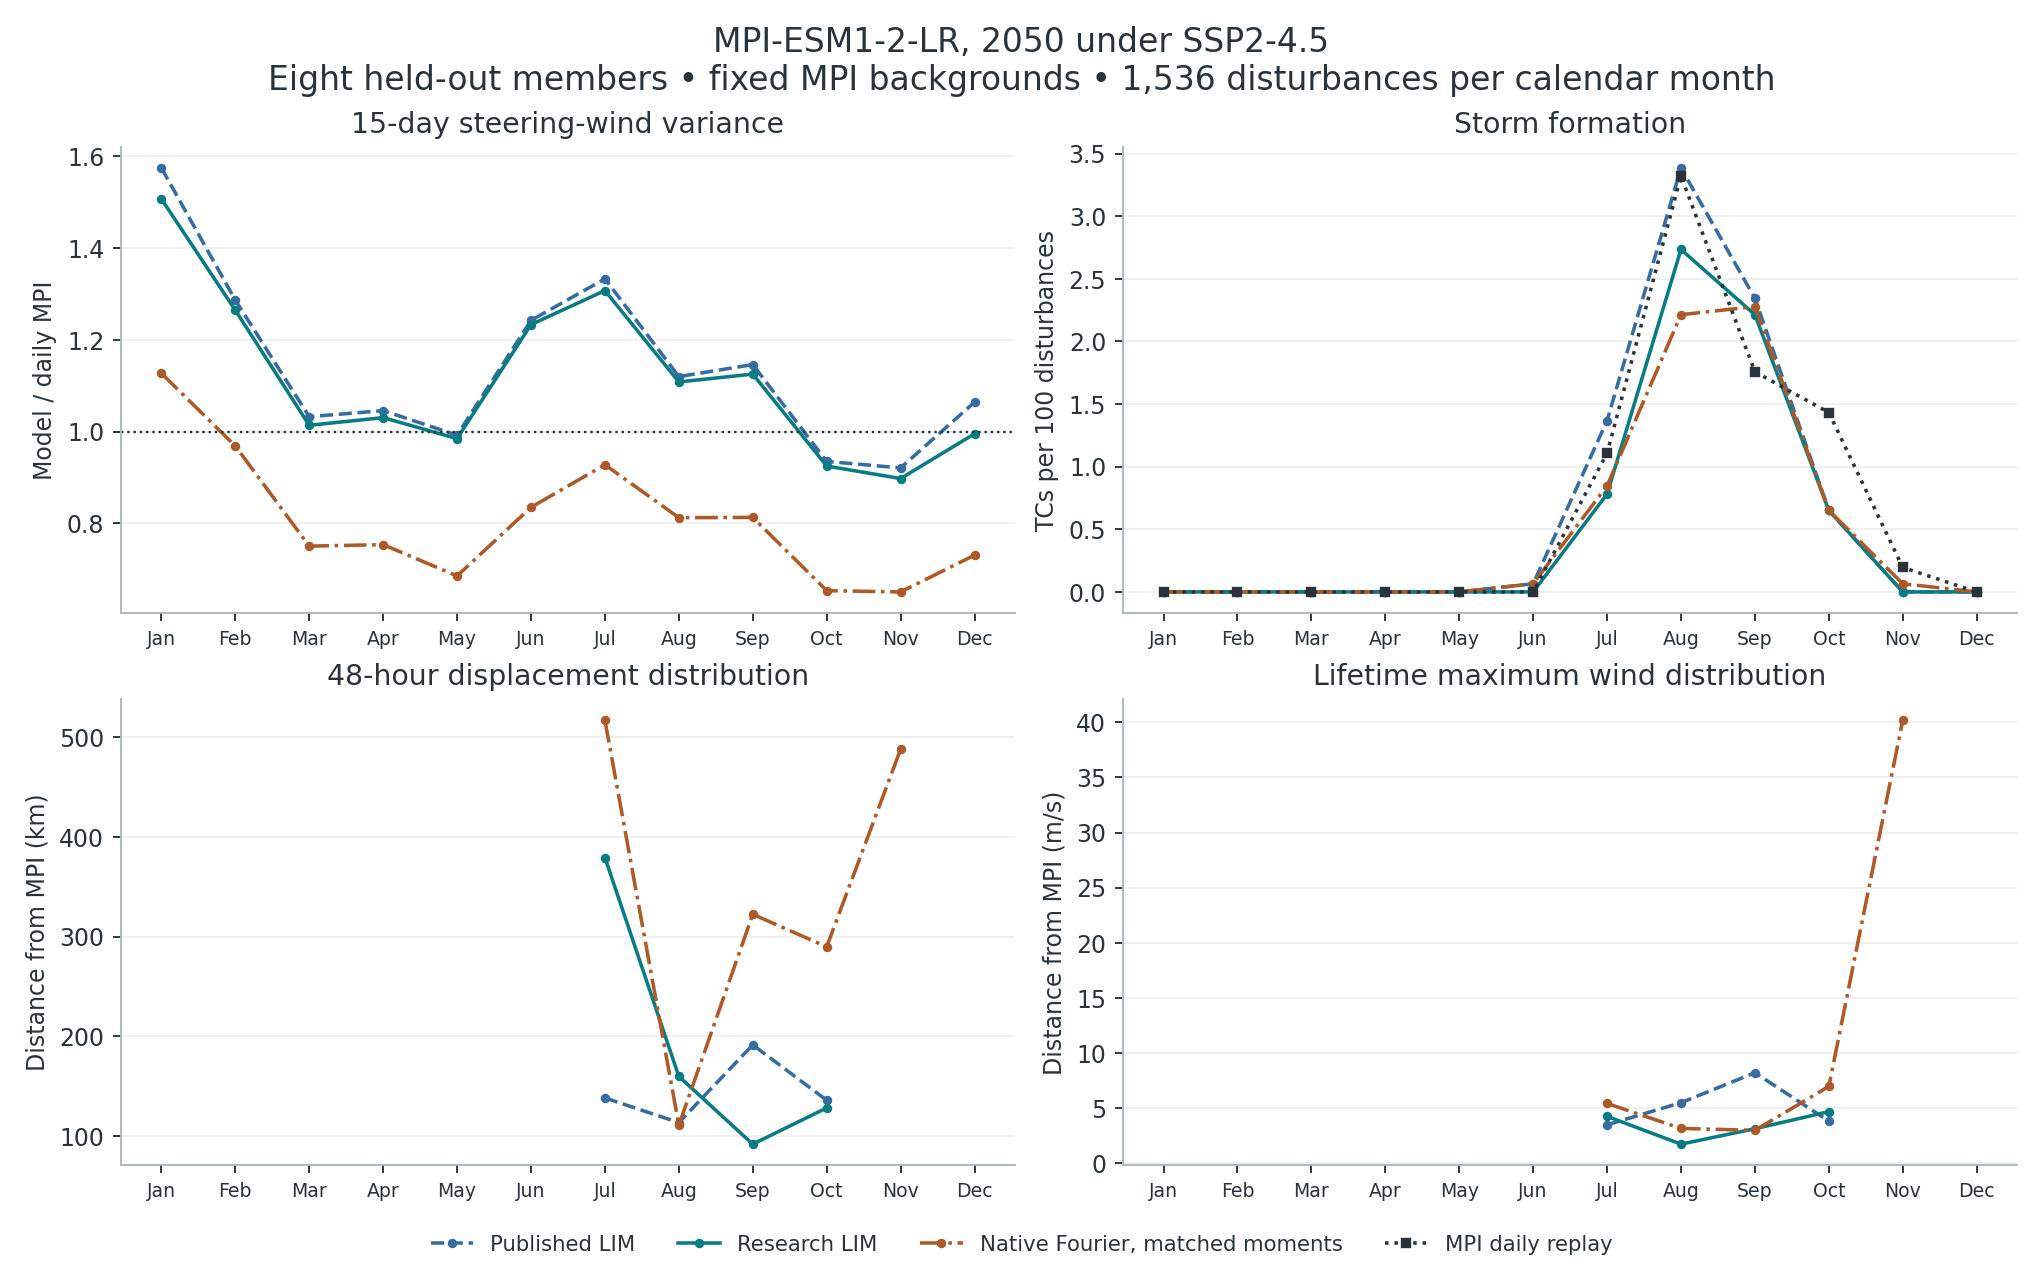

In [17]:
selected = json.loads((study / "freeze_receipt.json").read_text())["stage"]
annual = pd.read_csv(study_data / "annual_mpi2050_storms.csv", dtype={"month": str})
annual_attempts = pd.read_parquet(study_data / "annual_mpi2050_attempts.parquet")
annual_keys = ["year", "month", *seed_key]
fixed_rows = annual_attempts[annual_attempts.protocol.isin(["MPI daily", fixed_bg])]
annual_labels = {"mpi_daily": MPI, "published_v1": v1_label, selected: research_label,
                 "native_fourier": fourier_label, "selected_fourier": "Native Fourier (research moments)"}
annual_reference = fixed_rows[fixed_rows.model == "mpi_daily"]
assert len(annual_reference) == 8 * 12 * 2 * 96
panel = annual[(annual.month == "all") & (annual.protocol == fixed_bg)].set_index(["driver", "metric"])
rows = []
for tag, label in annual_labels.items():
    group = fixed_rows[fixed_rows.model == tag]
    check_disturbances(annual_reference, group, annual_keys)
    km = eligible_km(group)
    lmi = group.loc[group.tc, "lmi"].dropna()
    distance_error = wasserstein_distance(eligible_km(annual_reference), km)
    intensity_error = wasserstein_distance(annual_reference.loc[annual_reference.tc, "lmi"].dropna(), lmi)
    if tag != "mpi_daily":
        assert group.tc.sum() == panel.loc[(tag, "tc"), "tc"]
        np.testing.assert_allclose([distance_error, intensity_error],
                                   panel.loc[[(tag, "displacement_48h_km"), (tag, "lmi")], "error"])
    rows.append([label, int(group.tc.sum()), len(km), 100 * group.tc.mean(), distance_error, intensity_error])
table = pd.DataFrame(rows, columns=["Driver", "TCs", "48 h windows", "TCs per 100 seeds",
                                    "48 h displacement W1 (km)", "Lifetime peak wind W1 (m/s)"])
display(table.set_index("Driver").round(2))
display(Image(filename=str(study / "figures" / "ssp245_annual_tracks.png"), width=940))
display(Image(filename=str(study / "figures" / "ssp245_calendar.png"), width=940))

### Why the monthly displacement curve can look worse

Each map contains all accepted storms under that driver. Its colors identify starting months. For the July point in the lower-left plot, MPI, v1 and Research have only **15, 19 and 10** complete windows. Research moves farther from MPI in July and August and closer in September and October on this seed panel. In the annual panel’s September subset, W1 falls from 191.2 to 91.5 km with 23, 28 and 30 eligible MPI, v1 and Research windows. The larger September replay in section 6 has 370, 345 and 324 windows and ranks the versions the other way. The table below lists every month with a score for both versions. A gap means a required displacement sample is empty. November has two MPI windows and none in either LIM.

A year-level W1 pools the individual distances before computing the two distributions. Averaging the four displayed monthly W1 values gives a different statistic. Each driver can form a different subset of the same disturbances, and months then contribute different numbers of eligible windows. “Change” in the table and subsequent sections means **Research error minus v1 error**. A positive value is a larger error. Intervals pair the same eight MPI members across all drivers. Resamples with an empty distribution have undefined W1 and are counted separately in “Valid resamples”.

In [18]:
import calendar

# Validate the pooled and monthly scores against the positions of the actual annual storms.
version_tags = ["mpi_daily", "published_v1", selected]
annual_lims = fixed_rows[fixed_rows.model.isin(version_tags)]
annual_fixes = pd.read_parquet(study_data / "annual_mpi2050_tracks_6h.parquet")
annual_fixes = annual_fixes[annual_fixes.protocol.isin(["MPI daily", fixed_bg]) & annual_fixes.model.isin(version_tags)]
check_48h_tracks(annual_fixes, annual_lims, ["model", "protocol", *annual_keys])

month_rows = []
for month, group in annual_lims.groupby("month", sort=True):
    samples = [eligible_km(group[group.model == tag]) for tag in version_tags]
    if not all(len(x) for x in samples):
        continue
    old, new = [wasserstein_distance(samples[0], x) for x in samples[1:]]
    scores = annual[(annual.month == str(month)) & (annual.protocol == fixed_bg) &
                    (annual.metric == "displacement_48h_km")].set_index("driver")
    pair = scores.loc[selected + "_gain_vs_published_v1"]
    np.testing.assert_allclose([old, new, new - old],
                               [scores.at["published_v1", "error"], scores.at[selected, "error"], -pair.error])
    month_rows.append([calendar.month_name[month], *map(len, samples), old, new, new-old,
                       -pair.ci_high, -pair.ci_low, int(pair.valid_draws)])
monthly_displacement = pd.DataFrame(month_rows, columns=["Month", "MPI n", "v1 n", "Research n",
    "v1 W1 (km)", "Research W1 (km)", "Change (km)", "Lower 95%", "Upper 95%", "Valid resamples"])
display(monthly_displacement.set_index("Month").round(1))

,MPI n,v1 n,Research n,v1 W1 (km),Research W1 (km),Change (km),Lower 95%,Upper 95%,Valid resamples
Month,,,,,,,,,
July,15,19,10,137.9,379.4,241.4,-167.4,834.9,1500
August,42,50,36,113.2,159.5,46.4,-120.8,188.3,1500
September,23,28,30,191.2,91.5,-99.7,-197.6,186.7,1500
October,21,8,10,135.6,127.9,-7.7,-211.1,192.7,1497


### Where in the displacement distribution did the error change?

The left panel pools the annual storms. To read the right panel, line up the MPI and model storm distances from shortest to longest. At probability rank $p$, let $Q(p)$ be the corresponding displacement. The empirical $W_1$ is the integral of $|Q_{\rm model}(p)-Q_{\rm MPI}(p)|$ from zero to one. Integrate the gap over each quarter of that probability axis. Each bar shows **Research minus v1** for one quarter, in kilometres. The four bars for a given experiment add up to its total W1 change.

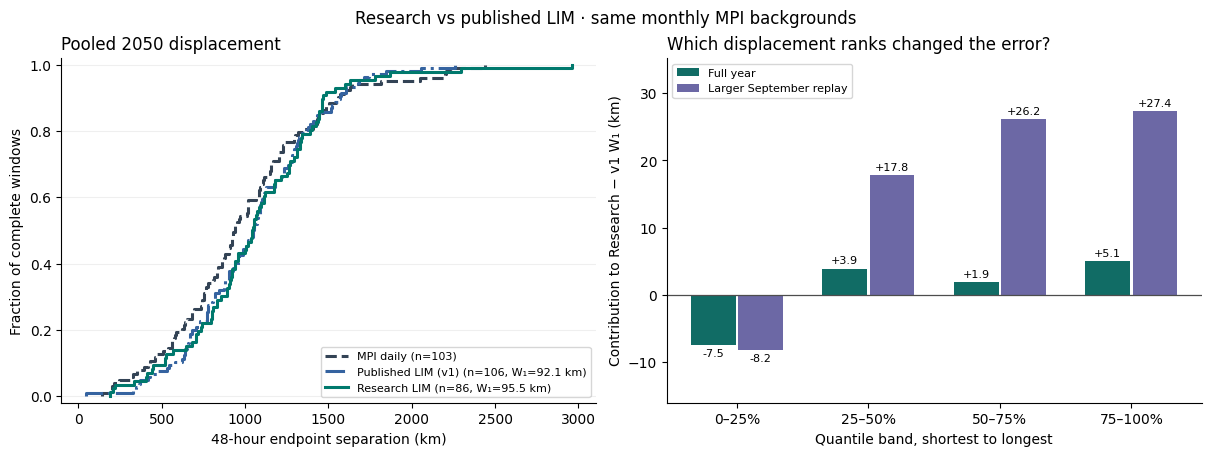

In [19]:
def quartile_w1(reference, model):
    """Exact contribution (km) of each quarter of the probability axis to empirical W1."""
    r, m = np.sort(reference), np.sort(model)
    boundaries = np.unique(np.r_[np.arange(len(r) + 1) / len(r), np.arange(len(m) + 1) / len(m),
                                 np.linspace(0, 1, 5)])
    mid = (boundaries[:-1] + boundaries[1:]) / 2
    # Each empirical quantile is constant between successive order-statistic boundaries.
    gap = np.abs(r[(mid * len(r)).astype(int)] - m[(mid * len(m)).astype(int)])
    pieces = np.bincount((4 * mid).astype(int), weights=np.diff(boundaries) * gap, minlength=4)
    np.testing.assert_allclose(pieces.sum(), wasserstein_distance(reference, model))
    return pieces


year_samples = {annual_labels[tag]: eligible_km(annual_lims[annual_lims.model == tag]) for tag in version_tags}
sept_samples = {MPI: reference_km}
for label in [v1_label, research_label]:
    sept_samples[label] = eligible_km(september[(september.protocol == fixed_bg) & (september.driver == label)])

fig, (cdf_ax, band_ax) = plt.subplots(1, 2, figsize=(12, 4.45), layout="constrained")
for label, sample in year_samples.items():
    w1 = wasserstein_distance(year_samples[MPI], sample)
    detail = f"n={len(sample)}" if label == MPI else f"n={len(sample)}, W₁={w1:.1f} km"
    cdf_ax.ecdf(sample, label=f"{label} ({detail})", color=version_colors[label],
                ls=version_styles[label], lw=2.2)
cdf_ax.set(title="Pooled 2050 displacement", xlabel="48-hour endpoint separation (km)",
           ylabel="Fraction of complete windows", ylim=(-.02, 1.02))
cdf_ax.legend(loc="lower right", fontsize=8)
cdf_ax.grid(axis="y", alpha=.2)

bands = np.arange(4)
for panel_label, values, offset, color in [("Full year", year_samples, -.18, "#116c65"),
                                         ("Larger September replay", sept_samples, .18, "#6c68a5")]:
    old = quartile_w1(values[MPI], values[v1_label])
    new = quartile_w1(values[MPI], values[research_label])
    bars = band_ax.bar(bands + offset, new - old, width=.34, color=color, label=panel_label)
    band_ax.bar_label(bars, labels=[f"{x:+.1f}" for x in new-old], fontsize=8, padding=2)
band_ax.axhline(0, color=".3", lw=.9)
band_ax.set(title="Which displacement ranks changed the error?", xlabel="Quantile band, shortest to longest",
            ylabel="Contribution to Research − v1 W₁ (km)", xticks=bands,
            xticklabels=["0–25%", "25–50%", "50–75%", "75–100%"])
band_ax.margins(y=.22)
band_ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Research vs published LIM · same monthly MPI backgrounds")
fig.savefig(mpi_out / "lim_versions_48h.png")
plt.show()

In the annual replay the shortest quarter reduced W1 by **7.5 km**. The other three quarters added **3.9, 1.9 and 5.1 km**, leaving an overall increase of **3.4 km** (paired 95% interval **−64.0 to +96.1 km**). In the larger September replay the shortest quarter also improved. The other three quarters added about **71 km** in total, giving a net increase of **63.1 km**. Both experiments compare each driver's eligible population. The breakdown locates the differences in the curves. Storm motion, genesis and survival can each affect the eligible population.

### How much does the mix of months affect the pooled result?

July through October are the months with at least one complete window in all three drivers. First pool just those months using each driver's own window counts. Then give each model the same monthly shares as MPI. For month $m$, each eligible model storm receives a weight proportional to $n_{\rm MPI,m}/n_{\rm model,m}$, where $n$ is the number of eligible storms. Windows within a month keep equal weight. The paired bootstrap recalculates those shares each time it resamples the eight members. A resample needs at least one window per driver in each of the four months to evaluate the common shares.

In [20]:
# Resample the same eight whole members in every driver and month, as in the annual benchmark.
members = sorted(annual_reference.member.unique())
rng = np.random.default_rng(840792)
replicates = rng.multinomial(len(members), np.full(len(members), 1/len(members)), size=1500)
member_counts = np.vstack([np.ones(len(members), dtype=int), replicates])
complete = annual_lims.loc[annual_lims.tc & np.isfinite(annual_lims.displacement_48h_km)]
common_months = sorted(set.intersection(*(set(complete.loc[complete.model == tag, "month"]) for tag in version_tags)))


def compare_month_mix(group, match_mpi_months):
    tracks = [group[group.model == tag] for tag in version_tags]  # MPI, published v1, Research
    km = [f.displacement_48h_km.to_numpy() for f in tracks]
    mo = [f.month.to_numpy() for f in tracks]
    member_index = [pd.Index(members).get_indexer(f.member) for f in tracks]
    scores = []
    for counts in member_counts:
        weights = [counts[i].astype(float) for i in member_index]
        if match_mpi_months:
            totals = [np.bincount(m, weights=w, minlength=13) for m, w in zip(mo, weights)]
            if any((t[common_months] == 0).any() for t in totals):
                scores.append([np.nan, np.nan])
                continue
            # Give the windows in month m a total weight equal to MPI's count in month m.
            for i in (1, 2):
                weights[i] *= totals[0][mo[i]] / totals[i][mo[i]]
        scores.append([wasserstein_distance(km[0], km[i], u_weights=weights[0], v_weights=weights[i])
                       for i in (1, 2)])
    result = np.asarray(scores)
    change = result[:, 1] - result[:, 0]
    valid = change[1:][np.isfinite(change[1:])]
    return [*result[0], change[0], *np.quantile(valid, [.025, .975]), len(valid)]


comparable = complete[complete.month.isin(common_months)]
mix = pd.DataFrame([
    compare_month_mix(complete, False),
    compare_month_mix(comparable, False),
    compare_month_mix(comparable, True),
], index=["All months, each driver's actual shares", "July–October, each driver's actual shares",
          "July–October, MPI month shares for all"], columns=["v1 W1 (km)", "Research W1 (km)",
          "Change (km)", "Lower 95%", "Upper 95%", "Valid resamples"])
archived = panel.loc[(selected + "_gain_vs_published_v1", "displacement_48h_km")]
np.testing.assert_allclose(mix.iloc[0, 2:5].astype(float), [-archived.error, -archived.ci_high, -archived.ci_low])
display(mix.round(1))

,v1 W1 (km),Research W1 (km),Change (km),Lower 95%,Upper 95%,Valid resamples
"All months, each driver's actual shares",92.1,95.5,3.4,-64.0,96.1,1500
"July–October, each driver's actual shares",91.0,98.7,7.7,-55.8,96.1,1500
"July–October, MPI month shares for all",91.2,107.3,16.1,-41.8,152.2,1497


For July–October the Research-minus-v1 gap is **+7.7 km** with each model's actual mix and **+16.1 km** with common MPI month shares. Equalizing the month mix leaves a larger point difference in this sample. Storms within each month can still differ in formation location, intensity and survival. Both paired intervals include zero.

## 8. What improved from published v1 to Research?

### Storm outcomes under the two annual input conditions

The selection score used ocean probability forecasts, conditional monthly wind error, and total and within-month wind variances on development members. Storm displacement was evaluated after the weights were fixed. With fixed MPI backgrounds FAST receives identical monthly physical ocean and thermodynamic fields across drivers. Each LIM encodes those fields with its own EOFs and supplies its own winds. A two-day storm displacement also depends on the start location, the wind along the moving track and whether the storm survives for nine fixes. In the warming-only rows, each LIM generates the environmental background as well.

The magnitudes below are errors against daily MPI-driven storms. For the two rates, a perfect score is zero even when the actual rate is positive. Each row has its own units. Intervals apply to the paired difference between the two errors and resample the eight members of this one year. [Selection criteria](../experiments/annual_refinement/decision.py) · [Annual storm scores](../reports/annual_refinement/data/annual_mpi2050_storms.csv)

In [21]:
# Each confidence interval comes from paired errors on the same resampled MPI members.
# The saved gain uses v1 minus Research. Negating both endpoints reverses that convention.
storm_metrics = {"displacement_48h_km": "48 h displacement W1 (km)", "lmi": "Lifetime peak wind W1 (m/s)",
                 "tc": "Formation rate absolute error (per 100)", "landfall": "Landfall rate absolute error (per 100)"}
storm_rows = []
for condition in (fixed_bg, "warming only"):
    pool = annual[(annual.month == "all") & (annual.protocol == condition)].set_index(["driver", "metric"])
    for metric, label in storm_metrics.items():
        old, new = [pool.at[(tag, metric), "error"] for tag in ("published_v1", selected)]
        pair = pool.loc[(selected + "_gain_vs_published_v1", metric)]
        np.testing.assert_allclose(new-old, -pair.error, atol=1e-12)
        storm_rows.append([condition, label, old, new, new-old, -pair.ci_high, -pair.ci_low])
storm_changes = pd.DataFrame(storm_rows, columns=["Annual 2050 inputs", "Error against MPI", "Published v1",
                                                 "Research", "Change", "Lower 95%", "Upper 95%"])
display(storm_changes.set_index(["Annual 2050 inputs", "Error against MPI"]).round(3))

Published v1  \
Annual 2050 inputs Error against MPI                                       
MPI background     48 h displacement W1 (km)                      92.088   
                   Lifetime peak wind W1 (m/s)                     4.870   
                   Formation rate absolute error (per 100)         0.000   
                   Landfall rate absolute error (per 100)          0.027   
warming only       48 h displacement W1 (km)                      95.229   
                   Lifetime peak wind W1 (m/s)                     2.736   
                   Formation rate absolute error (per 100)         0.092   
                   Landfall rate absolute error (per 100)          0.049   

                                                            Research  Change  \
Annual 2050 inputs Error against MPI                                           
MPI background     48 h displacement W1 (km)                  95.464   3.376   
                   Lifetime peak wind W1 (m/s)                 1.525  -3.345   
                   Formation rate absolute error (per 100)     0.119   0.119   
                   Landfall rate absolute error (per 100)      0.043   0.016   
warming only       48 h displacement W1 (km)                 124.863  29.634   
                   Lifetime peak wind W1 (m/s)                 3.190   0.454   
                   Formation rate absolute error (per 100)     0.179   0.087   
                   Landfall rate absolute error (per 100)      0.130   0.081   

                                                            Lower 95%  \
Annual 2050 inputs Error against MPI                                    
MPI background     48 h displacement W1 (km)                  -63.969   
                   Lifetime peak wind W1 (m/s)                 -5.339   
                   Formation rate absolute error (per 100)     -0.098   
                   Landfall rate absolute error (per 100)      -0.125   
warming only       48 h displacement W1 (km)                  -84.982   
                   Lifetime peak wind W1 (m/s)                 -2.460   
                   Formation rate absolute error (per 100)     -0.092   
                   Landfall rate absolute error (per 100)      -0.049   

                                                            Upper 95%  
Annual 2050 inputs Error against MPI                                   
MPI background     48 h displacement W1 (km)                   96.101  
                   Lifetime peak wind W1 (m/s)                  0.179  
                   Formation rate absolute error (per 100)      0.190  
                   Landfall rate absolute error (per 100)       0.141  
warming only       48 h displacement W1 (km)                  139.261  
                   Lifetime peak wind W1 (m/s)                  3.877  
                   Formation rate absolute error (per 100)      0.250  
                   Landfall rate absolute error (per 100)       0.179

With the MPI monthly background, Research reduces lifetime peak-wind W1 from **4.87 to 1.52 m/s**. Its paired difference is **−3.35 m/s** (95% interval **−5.34 to +0.18**). It forms **98** storms against **120** for both MPI and v1. When only warming is supplied, all four Research storm errors in this annual table increase. The seasonal development replay also illustrates the dependence on the sample. Across July, September and November in six validation years, fixed-background displacement W1 was 77.5 km for v1 and 51.4 km for Research. This development panel and the one-year 2050 test answer different questions. [Seasonal validation replay](../reports/annual_refinement/data/paired_seasonal_storms.csv)

### Environmental fields and steering winds

For each metric, compare Research and v1 against the **same actual MPI fields**. The first pair of columns uses all twelve months of SSP2-4.5 in 2050. The next pair uses nine additional cold, interior and warm climate years. Both panels use the same eight held-out member identities. The nine-year intervals also resample whole years within warming ranges.

Reconstruction RMSE measures how accurately the EOFs represent an observed map. CRPS scores the predicted distribution against the observed depth, in metres. Conditional monthly steering uses the observed monthly background. Initialized daily forecasts also see the last two observed wind maps. The two variance errors measure $|\log(V_{\rm model}/V_{\rm MPI})|$ for a 15-day average, with and without removing each month's mean.

In [22]:
# Both sides of a row use the same maps, members and months. Negative differences reduce error.
field_metrics = [
    ("projection_rmse", "basin/sst", "SST reconstruction RMSE (K)", 3),
    ("projection_rmse", "basin/mld", "Mixed-layer depth reconstruction RMSE (m)", 2),
    ("projection_rmse", "basin/gamma", "Subsurface gradient reconstruction RMSE (K/100 m)", 3),
    ("crps", "basin/mld", "Mixed-layer depth distribution CRPS (m)", 3),
    ("monthly_wind_rmse", "", "Conditional monthly steering RMSE (m/s)", 3),
    ("forecast_rmse", "1", "Initialized 1-day steering RMSE (m/s)", 3),
    ("forecast_rmse", "15", "Initialized 15-day steering RMSE (m/s)", 3),
    ("variance_log_error", "total/15", "15-day total wind variance |log ratio|", 3),
    ("variance_log_error", "within/15", "15-day within-month variance |log ratio|", 3),
]
field_results = {}
for panel_name, filename in [("2050", "paired_ssp245_year.csv"), ("Nine years", "paired_fresh.csv")]:
    scored = pd.read_csv(study_data / filename, dtype={"dimension": str}).fillna({"dimension": ""})
    scored = scored[scored.group == "all"].set_index(["metric", "dimension"])
    for metric, dimension, label, digits in field_metrics:
        row = scored.loc[(metric, dimension)]
        np.testing.assert_allclose(row.candidate-row.baseline, row.difference, atol=1e-12)
        result = field_results.setdefault(label, {})
        result[f"{panel_name} · v1 → Research"] = f"{row.baseline:.{digits}f} → {row.candidate:.{digits}f}"
        result[f"{panel_name} · change [95% interval]"] = (
            f"{row.difference:+.{digits}f} [{row.ci_low:+.{digits}f}, {row.ci_high:+.{digits}f}]"
        )
display(pd.DataFrame.from_dict(field_results, orient="index").rename_axis("Environmental error"))

,2050 · v1 → Research,2050 · change [95% interval],Nine years · v1 → Research,Nine years · change [95% interval]
Environmental error,,,,
SST reconstruction RMSE (K),0.424 → 0.327,"-0.097 [-0.103, -0.092]",0.452 → 0.341,"-0.111 [-0.114, -0.107]"
Mixed-layer depth reconstruction RMSE (m),19.70 → 15.28,"-4.42 [-5.20, -3.50]",37.81 → 30.73,"-7.08 [-9.86, -5.16]"
Subsurface gradient reconstruction RMSE (K/100 m),0.675 → 0.510,"-0.165 [-0.193, -0.143]",0.690 → 0.532,"-0.158 [-0.165, -0.151]"
Mixed-layer depth distribution CRPS (m),6.092 → 5.953,"-0.139 [-0.186, -0.090]",7.524 → 7.159,"-0.365 [-0.457, -0.274]"
Conditional monthly steering RMSE (m/s),0.857 → 0.790,"-0.067 [-0.071, -0.063]",0.915 → 0.804,"-0.111 [-0.133, -0.090]"
Initialized 1-day steering RMSE (m/s),2.882 → 2.902,"+0.020 [+0.018, +0.022]",2.896 → 2.916,"+0.020 [+0.019, +0.021]"
Initialized 15-day steering RMSE (m/s),5.076 → 5.059,"-0.017 [-0.021, -0.013]",5.100 → 5.072,"-0.028 [-0.034, -0.022]"
15-day total wind variance |log ratio|,0.146 → 0.133,"-0.014 [-0.022, -0.004]",0.035 → 0.024,"-0.010 [-0.016, +0.006]"
15-day within-month variance |log ratio|,0.112 → 0.108,"-0.003 [-0.013, +0.013]",0.032 → 0.042,"+0.009 [-0.011, +0.018]"


In 2050, mixed-layer depth reconstruction improves from **19.70 to 15.28 m** and conditional monthly steering from **0.857 to 0.790 m/s**. On the nine-year panel the corresponding errors fall from **37.81 to 30.73 m** and **0.915 to 0.804 m/s**. SST and subsurface gradient reconstruction improve on both panels. The initialized one-day forecast gets about **0.020 m/s worse** on each panel, while the initialized 15-day forecast gets slightly better. The table and displacement plots show where the environmental gains carry through to storms and where the observed scores move in the other direction. [Paired 2050 fields](../reports/annual_refinement/data/paired_ssp245_year.csv) · [Paired nine-year fields](../reports/annual_refinement/data/paired_fresh.csv)